In [1]:

# ============================================================
# SECTION 1 — XAI ENVIRONMENT AND PROJECT PATHS
# ============================================================

import sys
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms

from PIL import Image

from spikingjelly.activation_based import functional

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

# Your laptop uses CPU for this project.
DEVICE = torch.device("cpu")

# ------------------------------------------------------------
# Locate the Neuro Kiosk project root
# ------------------------------------------------------------

candidates = [Path.cwd(), *Path.cwd().parents]

PROJECT_ROOT = None

for path in candidates:
    if (
        (path / "models" / "densenet121_pneumonia_snn.pt").exists()
        and (path / "samples").exists()
    ):
        PROJECT_ROOT = path
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot locate Neuro Kiosk project root. "
        "Open this notebook from the project directory."
    )

MODEL_PATH = (
    PROJECT_ROOT
    / "models"
    / "densenet121_pneumonia_snn.pt"
)

NORMAL_IMAGE_PATH = (
    PROJECT_ROOT / "samples" / "sample_normal.png"
)

PNEUMONIA_IMAGE_PATH = (
    PROJECT_ROOT / "samples" / "sample_pneumonia.png"
)

METADATA_PATH = PROJECT_ROOT / "models" / "metadata.json"

print("\nProject root:", PROJECT_ROOT)
print("SNN checkpoint exists:", MODEL_PATH.exists())
print("NORMAL sample exists:", NORMAL_IMAGE_PATH.exists())
print("PNEUMONIA sample exists:", PNEUMONIA_IMAGE_PATH.exists())
print("Metadata exists:", METADATA_PATH.exists())

assert MODEL_PATH.exists()
assert NORMAL_IMAGE_PATH.exists()
assert PNEUMONIA_IMAGE_PATH.exists()

# ------------------------------------------------------------
# XAI experiment configuration
# ------------------------------------------------------------

XAI_TIMESTEPS = 16

# Validation-selected SNN T16 classification threshold
XAI_THRESHOLD = 0.9999173879623413

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

print("\nXAI configuration ready.")


Python: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
PyTorch: 2.6.0+cpu
CUDA available: False

Project root: c:\Users\eswar\.vscode\cpp\neuro_kiosk
SNN checkpoint exists: True
NORMAL sample exists: True
PNEUMONIA sample exists: True
Metadata exists: True

XAI configuration ready.


In [2]:

# ============================================================
# SECTION 2 — LOAD SAVED DENSENET121 SNN
# ============================================================

print("Loading converted DenseNet121 SNN...")

# This is our own trusted serialized FX GraphModule.
snn_model = torch.load(
    MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

if not isinstance(snn_model, nn.Module):
    raise TypeError("Loaded checkpoint is not a PyTorch model.")

snn_model = snn_model.to(DEVICE)
snn_model.eval()

# Count converted spiking neurons
spiking_modules = [
    (name, module)
    for name, module in snn_model.named_modules()
    if "IFNode" in type(module).__name__
    or "LIFNode" in type(module).__name__
]

# Count convolutional modules
conv_modules = [
    (name, module)
    for name, module in snn_model.named_modules()
    if isinstance(module, nn.Conv2d)
]

print("\nMODEL LOADED SUCCESSFULLY")

print("Model type:", type(snn_model).__name__)
print("Device:", DEVICE)
print("Convolutional modules:", len(conv_modules))
print("Spiking neuron modules:", len(spiking_modules))

print("\nLast convolutional modules:")

for name, module in conv_modules[-5:]:
    print(name, ":", module)

print("\nSpiking neuron examples:")

for name, module in spiking_modules[:5]:
    print(name, ":", type(module).__name__)

print("\nSNN loading complete.")


Loading converted DenseNet121 SNN...

MODEL LOADED SUCCESSFULLY
Model type: GraphModule
Device: cpu
Convolutional modules: 120
Spiking neuron modules: 121

Last convolutional modules:
features.denseblock4.denselayer14.conv2 : Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False, step_mode=s)
features.denseblock4.denselayer15.conv1 : Conv2d(960, 128, kernel_size=(1, 1), stride=(1, 1), step_mode=s)
features.denseblock4.denselayer15.conv2 : Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False, step_mode=s)
features.denseblock4.denselayer16.conv1 : Conv2d(992, 128, kernel_size=(1, 1), stride=(1, 1), step_mode=s)
features.denseblock4.denselayer16.conv2 : Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False, step_mode=s)

Spiking neuron examples:
features.denseblock1.denselayer1.ltb_spiking_0.if_node : HalfThresholdIFNode
features.denseblock1.denselayer1.ltb_spiking_1.if_node : HalfThresholdIFNode
features.denseblock1

NORMAL tensor: torch.Size([1, 3, 224, 224])
PNEUMONIA tensor: torch.Size([1, 3, 224, 224])


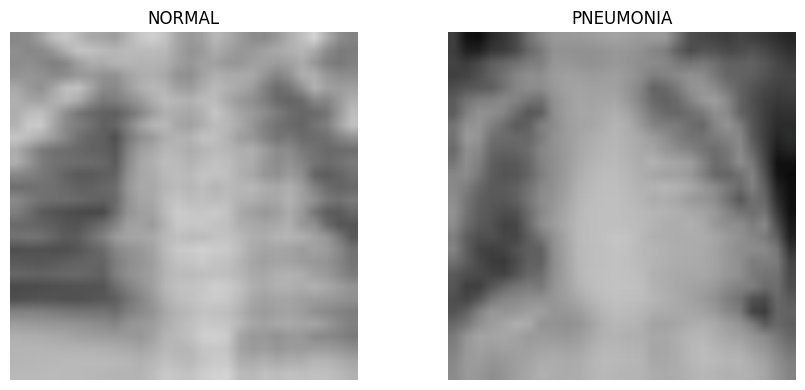

In [3]:

# ============================================================
# SECTION 3 — IMAGE PREPROCESSING AND SAMPLE LOADING
# ============================================================

preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


def load_xray(path):

    image = Image.open(path).convert("L")

    tensor = preprocess(image).unsqueeze(0)

    return tensor.to(DEVICE)


normal_image = load_xray(NORMAL_IMAGE_PATH)

pneumonia_image = load_xray(PNEUMONIA_IMAGE_PATH)

xai_samples = {
    "NORMAL": normal_image,
    "PNEUMONIA": pneumonia_image
}

print("NORMAL tensor:", normal_image.shape)
print("PNEUMONIA tensor:", pneumonia_image.shape)

# Display the original samples
fig, axes = plt.subplots(1, 2, figsize=(9, 4))

for ax, (label, tensor) in zip(axes, xai_samples.items()):

    # Undo ImageNet normalization for visualization
    image = tensor[0].detach().cpu()

    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

    image = (image * std + mean).clamp(0, 1)

    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(label)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [4]:

# ============================================================
# SECTION 4 — SNN PREDICTION VERIFICATION
# ============================================================

def run_snn_inference(image, timesteps=XAI_TIMESTEPS):

    functional.reset_net(snn_model)

    outputs = []

    try:
        with torch.no_grad():

            for _ in range(timesteps):

                output = snn_model(image)

                if not torch.is_tensor(output):
                    raise TypeError(
                        f"Unexpected output type: {type(output)}"
                    )

                outputs.append(output.reshape(1, -1))

        average_logits = torch.stack(
            outputs, dim=0
        ).mean(dim=0)

        if average_logits.shape != (1, 1):
            raise RuntimeError(
                f"Expected binary output [1,1], "
                f"got {tuple(average_logits.shape)}"
            )

        score = torch.sigmoid(average_logits[0, 0]).item()

        prediction = (
            "PNEUMONIA"
            if score >= XAI_THRESHOLD
            else "NORMAL"
        )

        return score, prediction

    finally:
        functional.reset_net(snn_model)


for label, image in xai_samples.items():

    score, prediction = run_snn_inference(image)

    print("\nActual sample:", label)
    print("Predicted:", prediction)
    print("Pneumonia score:", round(score, 6))
    print("Threshold:", XAI_THRESHOLD)



Actual sample: NORMAL
Predicted: NORMAL
Pneumonia score: 0.999366
Threshold: 0.9999173879623413

Actual sample: PNEUMONIA
Predicted: NORMAL
Pneumonia score: 0.999304
Threshold: 0.9999173879623413


In [5]:

# ============================================================
# SECTION 5 — TIMESTEP OUTPUT DIAGNOSTICS
# ============================================================

thresholds = {
    8: 0.9987940788269043,
    16: 0.9999173879623413
}


def inspect_timestep_outputs(image, sample_name, timesteps):

    functional.reset_net(snn_model)

    step_logits = []

    try:
        with torch.no_grad():

            for t in range(timesteps):

                output = snn_model(image)

                step_logits.append(
                    output.detach().reshape(-1)[0].item()
                )

        # Same averaging approach used in model evaluation
        average_logit = float(np.mean(step_logits))

        score = float(
            torch.sigmoid(
                torch.tensor(average_logit)
            ).item()
        )

        threshold = thresholds[timesteps]

        prediction = (
            "PNEUMONIA"
            if score >= threshold
            else "NORMAL"
        )

        print("\n" + "=" * 55)
        print("SAMPLE:", sample_name)
        print("TIMESTEPS:", timesteps)
        print("=" * 55)

        print("Individual timestep logits:")
        print(np.round(step_logits, 5))

        print("Average logit:", average_logit)
        print("Pneumonia score:", score)
        print("Classification threshold:", threshold)
        print("Prediction:", prediction)

        return {
            "sample": sample_name,
            "timesteps": timesteps,
            "step_logits": step_logits,
            "average_logit": average_logit,
            "score": score,
            "prediction": prediction
        }

    finally:
        functional.reset_net(snn_model)


timestep_diagnostics = {}

for sample_name, image in xai_samples.items():

    for T in [8, 16]:

        result = inspect_timestep_outputs(
            image,
            sample_name,
            T
        )

        timestep_diagnostics[
            (sample_name, T)
        ] = result


print("\nSNN STRUCTURE SUMMARY")
print("Convolutional modules:", len(conv_modules))
print("Spiking neuron modules:", len(spiking_modules))
print("Total parameters:", sum(
    p.numel() for p in snn_model.parameters()
))



SAMPLE: NORMAL
TIMESTEPS: 8
Individual timestep logits:
[3.35428 6.26915 6.75628 7.15676 7.37881 7.60026 7.98305 8.06683]
Average logit: 6.820678144693375
Pneumonia score: 0.9989101886749268
Classification threshold: 0.9987940788269043
Prediction: PNEUMONIA

SAMPLE: NORMAL
TIMESTEPS: 16
Individual timestep logits:
[3.35428 6.26915 6.75628 7.15676 7.37881 7.60026 7.98305 8.06683 7.85036
 7.79291 8.15786 7.75404 8.09952 7.92781 7.8917  7.76202]
Average logit: 7.362603381276131
Pneumonia score: 0.9993658661842346
Classification threshold: 0.9999173879623413
Prediction: NORMAL

SAMPLE: PNEUMONIA
TIMESTEPS: 8
Individual timestep logits:
[1.55156 4.97893 5.08536 5.96121 6.32153 7.32205 7.18863 8.23455]
Average logit: 5.83047778904438
Pneumonia score: 0.9970718622207642
Classification threshold: 0.9987940788269043
Prediction: NORMAL

SAMPLE: PNEUMONIA
TIMESTEPS: 16
Individual timestep logits:
[1.55156 4.97893 5.08536 5.96121 6.32153 7.32205 7.18863 8.23455 8.38269
 8.90032 8.33683 9.13737 8.

In [6]:

# ============================================================
# SECTION 6 — GRADIENT FLOW TEST FOR DENSENET121 SNN
# Foundation for SNN-Grad2D, Grad3D and SNN-CAM
# ============================================================

import torch
import numpy as np
from spikingjelly.activation_based import functional

snn_model.eval()

# Use T=16, matching the selected XAI configuration.
T = 16
threshold = 0.9999173879623413

# Use the PNEUMONIA sample first.
x = xai_samples["PNEUMONIA"].detach().clone()

# ------------------------------------------------------------
# 1. Get the final convolutional module
# ------------------------------------------------------------

conv_modules = [
    (name, module)
    for name, module in snn_model.named_modules()
    if isinstance(module, nn.Conv2d)
]

if not conv_modules:
    raise RuntimeError("No Conv2d modules found.")

last_conv_name, last_conv_module = conv_modules[-1]

print("Selected convolution:", last_conv_name)
print("Module:", last_conv_module)

# ------------------------------------------------------------
# 2. Prepare an independent input at every timestep
# ------------------------------------------------------------

x_seq = (
    x.unsqueeze(0)
    .repeat(T, 1, 1, 1, 1)
    .detach()
    .clone()
    .requires_grad_(True)
)

print("Input sequence shape:", tuple(x_seq.shape))

# ------------------------------------------------------------
# 3. Record convolutional activations using a hook
# ------------------------------------------------------------

conv_activations = []

def save_conv_activation(module, inputs, output):

    if torch.is_tensor(output):
        conv_activations.append(output)

hook = last_conv_module.register_forward_hook(
    save_conv_activation
)

# ------------------------------------------------------------
# 4. Forward pass through all timesteps
# ------------------------------------------------------------

logits_per_step = []

try:

    functional.reset_net(snn_model)
    snn_model.zero_grad(set_to_none=True)

    for t in range(T):

        step_output = snn_model(x_seq[t])

        if not torch.is_tensor(step_output):
            raise TypeError(
                "Unexpected output type: "
                + str(type(step_output))
            )

        step_output = step_output.reshape(1, -1)

        if step_output.shape[1] != 1:
            raise RuntimeError(
                "Expected one binary logit. Got "
                + str(tuple(step_output.shape))
            )

        logits_per_step.append(step_output[:, 0])

    logits = torch.stack(
        logits_per_step,
        dim=0
    )

    average_logit = logits.mean()

    pneumonia_score = torch.sigmoid(
        average_logit.detach()
    ).item()

    predicted_class = int(
        pneumonia_score >= threshold
    )

    # --------------------------------------------------------
    # 5. Define the target score for binary classification
    # --------------------------------------------------------

    if predicted_class == 1:
        target_score = logits.sum()
        target_name = "PNEUMONIA"
    else:
        target_score = -logits.sum()
        target_name = "NORMAL"

    print("\nPrediction:", target_name)
    print("Pneumonia score:", pneumonia_score)
    print("Target score:", target_score.item())

    print("\nCaptured convolution activations:",
          len(conv_activations))

    # --------------------------------------------------------
    # 6. Calculate gradients with respect to:
    #    A. Input sequence
    #    B. Last convolution activations
    # --------------------------------------------------------

    gradient_targets = [x_seq] + conv_activations

    gradients = torch.autograd.grad(
        outputs=target_score,
        inputs=gradient_targets,
        allow_unused=True,
        retain_graph=False
    )

    input_gradient = gradients[0]
    conv_gradients = gradients[1:]

    # --------------------------------------------------------
    # 7. Inspect input gradients
    # --------------------------------------------------------

    if input_gradient is None:

        print("\nINPUT GRADIENT: NOT AVAILABLE")

    else:

        print("\nINPUT GRADIENT: AVAILABLE")
        print("Shape:", tuple(input_gradient.shape))

        print(
            "Mean absolute gradient:",
            input_gradient.abs().mean().item()
        )

        print(
            "Maximum absolute gradient:",
            input_gradient.abs().max().item()
        )

        print(
            "All finite:",
            torch.isfinite(input_gradient).all().item()
        )

        print(
            "Non-zero values:",
            torch.count_nonzero(input_gradient).item()
        )

    # --------------------------------------------------------
    # 8. Inspect convolutional gradients
    # --------------------------------------------------------

    valid_conv_gradients = [
        g for g in conv_gradients
        if g is not None
    ]

    print("\nCONVOLUTION GRADIENTS")
    print("Available:", len(valid_conv_gradients))
    print("Total:", len(conv_gradients))

    for i, grad in enumerate(conv_gradients):

        if grad is None:
            print(f"Timestep {i+1}: None")
        else:
            print(
                f"Timestep {i+1}:",
                tuple(grad.shape),
                "| mean abs:",
                grad.abs().mean().item()
            )

    # --------------------------------------------------------
    # 9. Final compatibility status
    # --------------------------------------------------------

    input_ok = (
        input_gradient is not None
        and torch.isfinite(input_gradient).all().item()
        and torch.count_nonzero(input_gradient).item() > 0
    )

    conv_ok = (
        len(valid_conv_gradients) > 0
    )

    print("\n" + "=" * 55)
    print("XAI GRADIENT COMPATIBILITY")
    print("=" * 55)

    print("Input gradients:", input_ok)
    print("Convolution gradients:", conv_ok)

    if input_ok and conv_ok:
        print("RESULT: GRADIENT METHODS ARE COMPATIBLE")
    else:
        print("RESULT: INVESTIGATION REQUIRED")

finally:

    hook.remove()
    functional.reset_net(snn_model)


Selected convolution: features.denseblock4.denselayer16.conv2
Module: Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False, step_mode=s)
Input sequence shape: (16, 1, 3, 224, 224)

Prediction: NORMAL
Pneumonia score: 0.9993041753768921
Target score: -116.31462860107422

Captured convolution activations: 16

INPUT GRADIENT: AVAILABLE
Shape: (16, 1, 3, 224, 224)
Mean absolute gradient: 0.002630626317113638
Maximum absolute gradient: 0.1847705990076065
All finite: True
Non-zero values: 2408448

CONVOLUTION GRADIENTS
Available: 16
Total: 16
Timestep 1: (1, 32, 7, 7) | mean abs: 0.016010720282793045
Timestep 2: (1, 32, 7, 7) | mean abs: 0.014310641214251518
Timestep 3: (1, 32, 7, 7) | mean abs: 0.013580803759396076
Timestep 4: (1, 32, 7, 7) | mean abs: 0.01322623435407877
Timestep 5: (1, 32, 7, 7) | mean abs: 0.012900297529995441
Timestep 6: (1, 32, 7, 7) | mean abs: 0.012593812309205532
Timestep 7: (1, 32, 7, 7) | mean abs: 0.012174775823950768
Timestep 8: (1, 32, 

In [7]:

# ============================================================
# SECTION 7 — SNN-GRAD3D AND SNN-GRAD2D
# Adapted from mentor's SNN explainability implementation
# ============================================================

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

from spikingjelly.activation_based import functional


# ------------------------------------------------------------
# 1. Prediction helper
# ------------------------------------------------------------

def predict_for_xai(image, timesteps=16):

    functional.reset_net(snn_model)

    try:
        with torch.no_grad():

            step_logits = []

            for t in range(timesteps):

                output = snn_model(image)

                step_logits.append(
                    output.reshape(-1)[0]
                )

            average_logit = torch.stack(
                step_logits
            ).mean()

            pneumonia_score = torch.sigmoid(
                average_logit
            ).item()

            predicted_class = int(
                pneumonia_score >= XAI_THRESHOLD
            )

        return predicted_class, pneumonia_score

    finally:
        functional.reset_net(snn_model)


# ------------------------------------------------------------
# 2. Channel reduction
# Same abs_sum approach as mentor's notebook
# ------------------------------------------------------------

def reduce_channels(attr, mode="abs_sum"):

    # Input: [T,C,H,W]
    if attr.ndim != 4:
        raise ValueError(
            f"Expected [T,C,H,W], got {attr.shape}"
        )

    if mode == "abs_sum":
        return attr.abs().sum(dim=1)

    elif mode == "abs_mean":
        return attr.abs().mean(dim=1)

    elif mode == "sum":
        return attr.sum(dim=1)

    elif mode == "max_abs":
        return attr.abs().max(dim=1).values

    raise ValueError(f"Unknown mode: {mode}")


# ------------------------------------------------------------
# 3. Time reduction
# Same sum/mean/max approach as mentor's notebook
# ------------------------------------------------------------

def reduce_time(maps_3d, mode="sum"):

    # Input: [T,H,W]

    if mode == "sum":
        return maps_3d.sum(dim=0)

    elif mode == "mean":
        return maps_3d.mean(dim=0)

    elif mode == "max":
        return maps_3d.max(dim=0).values

    raise ValueError(f"Unknown time reduction: {mode}")


# ------------------------------------------------------------
# 4. SNN-GRAD3D
# ------------------------------------------------------------

def snn_grad3d(
    model,
    image,
    timesteps=16,
    target_class=None,
    channel_reduce_mode="abs_sum"
):

    model.eval()

    # Obtain the model's predicted class.
    pred_class, pneumonia_score = predict_for_xai(
        image,
        timesteps
    )

    if target_class is None:
        target_class = pred_class

    # Create an independently differentiable input
    # for every timestep.
    x_seq = (
        image.unsqueeze(0)
        .repeat(timesteps, 1, 1, 1, 1)
        .detach()
        .clone()
        .requires_grad_(True)
    )

    model.zero_grad(set_to_none=True)
    functional.reset_net(model)

    try:

        # Forward through all timesteps.
        step_logits = []

        with torch.enable_grad():

            for t in range(timesteps):

                output = model(x_seq[t])

                step_logits.append(
                    output.reshape(-1)[0]
                )

            logits = torch.stack(step_logits)

            # Binary target score.
            # Class 1 = PNEUMONIA.
            # Class 0 = NORMAL.
            target_sign = (
                1.0 if target_class == 1 else -1.0
            )

            target_score = target_sign * logits.sum()

            # Gradient of target score w.r.t.
            # input sequence.
            gradients = torch.autograd.grad(
                outputs=target_score,
                inputs=x_seq,
                retain_graph=False,
                create_graph=False
            )[0]

        # [T,1,C,H,W] -> [T,C,H,W]
        gradients = gradients[:, 0]

        # [T,C,H,W] -> [T,H,W]
        heat3d = reduce_channels(
            gradients,
            mode=channel_reduce_mode
        )

        return (
            heat3d.detach(),
            target_class,
            pred_class,
            pneumonia_score
        )

    finally:

        functional.reset_net(model)
        model.zero_grad(set_to_none=True)


# ------------------------------------------------------------
# 5. SNN-GRAD2D
# Derived from Grad3D by reducing over time.
# ------------------------------------------------------------

def snn_grad2d(
    model,
    image,
    timesteps=16,
    target_class=None,
    channel_reduce_mode="abs_sum",
    time_reduce_mode="sum"
):

    heat3d, target_class, pred_class, score = snn_grad3d(
        model,
        image,
        timesteps=timesteps,
        target_class=target_class,
        channel_reduce_mode=channel_reduce_mode
    )

    heat2d = reduce_time(
        heat3d,
        mode=time_reduce_mode
    )

    return (
        heat2d,
        heat3d,
        target_class,
        pred_class,
        score
    )


print("SNN-Grad3D and SNN-Grad2D functions created.")


SNN-Grad3D and SNN-Grad2D functions created.


In [8]:

# ============================================================
# SECTION 7.1 — GENERATE GRADIENT EXPLANATIONS
# ============================================================

# Start with the PNEUMONIA sample.
# The model currently predicts NORMAL for this image.
xai_image = xai_samples["PNEUMONIA"]

(
    grad2d,
    grad3d,
    target_class,
    predicted_class,
    pneumonia_score
) = snn_grad2d(
    snn_model,
    xai_image,
    timesteps=16,
    channel_reduce_mode="abs_sum",
    time_reduce_mode="sum"
)

class_names = {
    0: "NORMAL",
    1: "PNEUMONIA"
}

print("True sample label: PNEUMONIA")
print("Model prediction:", class_names[predicted_class])
print("Explanation target:", class_names[target_class])
print("Pneumonia score:", pneumonia_score)

print("\nGrad2D shape:", tuple(grad2d.shape))
print("Grad3D shape:", tuple(grad3d.shape))

print("Grad2D maximum:", grad2d.max().item())
print("Grad3D maximum:", grad3d.max().item())

print("Grad2D finite:", torch.isfinite(grad2d).all().item())
print("Grad3D finite:", torch.isfinite(grad3d).all().item())

assert grad2d.shape == (224, 224)
assert grad3d.shape == (16, 224, 224)

assert torch.isfinite(grad2d).all()
assert torch.isfinite(grad3d).all()

print("\nGradient explanations generated successfully.")


True sample label: PNEUMONIA
Model prediction: NORMAL
Explanation target: NORMAL
Pneumonia score: 0.9993041753768921

Grad2D shape: (224, 224)
Grad3D shape: (16, 224, 224)
Grad2D maximum: 1.0978877544403076
Grad3D maximum: 0.38166457414627075
Grad2D finite: True
Grad3D finite: True

Gradient explanations generated successfully.


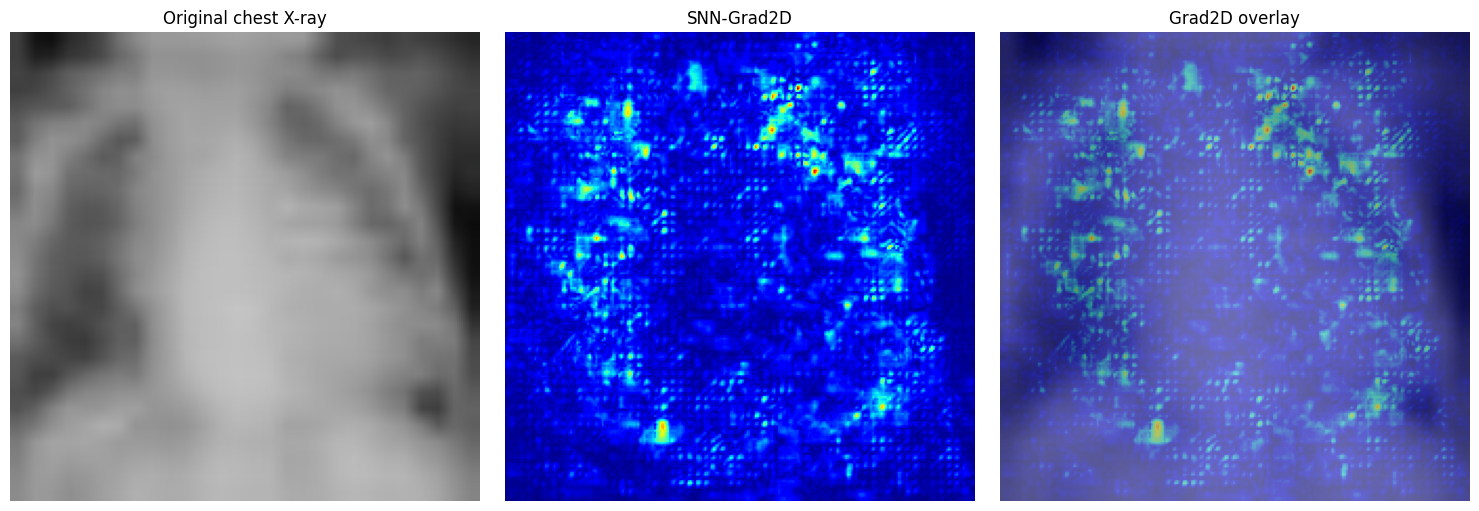

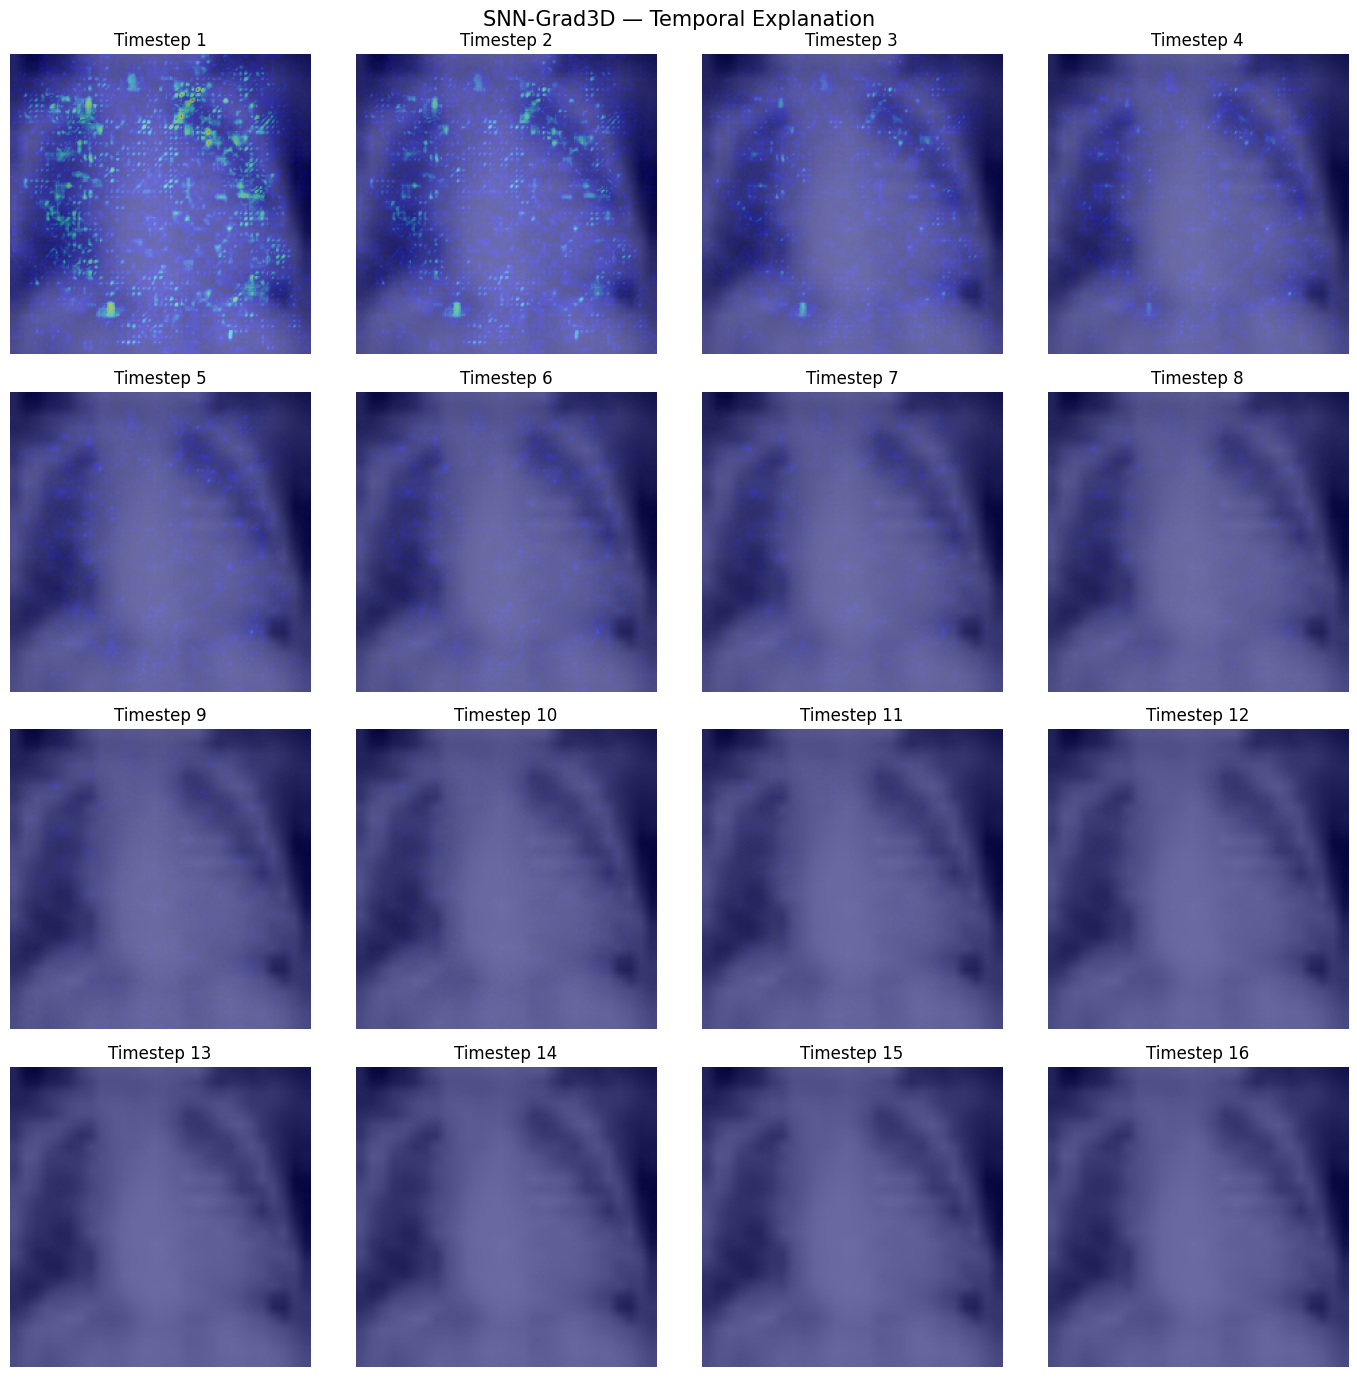

In [9]:

# ============================================================
# SECTION 7.2 — GRAD2D AND GRAD3D VISUALIZATION
# ============================================================

def denormalize_xray(tensor):

    image = tensor[0].detach().cpu().clone()

    mean = torch.tensor(
        IMAGENET_MEAN
    ).view(3, 1, 1)

    std = torch.tensor(
        IMAGENET_STD
    ).view(3, 1, 1)

    image = image * std + mean

    return image.clamp(0, 1).permute(1, 2, 0).numpy()


def normalize_map(heatmap, eps=1e-8):

    heatmap = heatmap.detach().float().cpu()

    heatmap = heatmap - heatmap.min()

    return heatmap / (heatmap.max() + eps)


original_image = denormalize_xray(xai_image)

# ------------------------------------------------------------
# GRAD2D
# ------------------------------------------------------------

grad2d_norm = normalize_map(grad2d)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(original_image)
axes[0].set_title("Original chest X-ray")

axes[1].imshow(grad2d_norm, cmap="jet")
axes[1].set_title("SNN-Grad2D")

axes[2].imshow(original_image)
axes[2].imshow(
    grad2d_norm,
    cmap="jet",
    alpha=0.45
)
axes[2].set_title("Grad2D overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# GRAD3D — 16 TIMESTEP MAPS
# Use one common scale for temporal comparison.
# ------------------------------------------------------------

global_max = grad3d.max().item() + 1e-8

fig, axes = plt.subplots(
    4, 4,
    figsize=(14, 14)
)

for t, ax in enumerate(axes.flat):

    temporal_map = (
        grad3d[t].detach().cpu() / global_max
    )

    ax.imshow(original_image)
    ax.imshow(
        temporal_map,
        cmap="jet",
        alpha=0.45,
        vmin=0,
        vmax=1
    )

    ax.set_title(f"Timestep {t+1}")
    ax.axis("off")

plt.suptitle(
    "SNN-Grad3D — Temporal Explanation",
    fontsize=15
)

plt.tight_layout()
plt.show()


In [10]:

# ============================================================
# SECTION 8 — SNN INTEGRATED GRADIENTS
# IG2D and IG3D
# ============================================================

from tqdm.auto import tqdm
from spikingjelly.activation_based import functional


# ------------------------------------------------------------
# 1. Baseline creation
# Matches the mentor's baseline definition.
# ------------------------------------------------------------

def make_xai_baseline(image, mode="black"):

    if mode == "zero":
        return torch.zeros_like(image)

    if mode not in ["black", "gray", "white"]:
        raise ValueError(f"Unknown baseline mode: {mode}")

    raw_value = {
        "black": 0.0,
        "gray": 0.5,
        "white": 1.0
    }[mode]

    mean = torch.tensor(
        IMAGENET_MEAN,
        device=image.device
    ).view(1, 3, 1, 1)

    std = torch.tensor(
        IMAGENET_STD,
        device=image.device
    ).view(1, 3, 1, 1)

    raw_image = torch.full_like(image, raw_value)

    return (raw_image - mean) / std


# ------------------------------------------------------------
# 2. Channel reduction
# Supports both [C,H,W] and [T,C,H,W].
# Matches mentor's abs_sum formulation.
# ------------------------------------------------------------

def mentor_channel_reduce(attr, mode="abs_sum"):

    if attr.ndim == 3:
        channel_dim = 0

    elif attr.ndim == 4:
        channel_dim = 1

    else:
        raise ValueError(
            f"Unexpected attribution shape: {attr.shape}"
        )

    if mode == "abs_sum":
        return attr.abs().sum(dim=channel_dim)

    elif mode == "abs_mean":
        return attr.abs().mean(dim=channel_dim)

    elif mode == "sum":
        return attr.sum(dim=channel_dim)

    elif mode == "max_abs":
        return attr.abs().max(dim=channel_dim).values

    raise ValueError(f"Unknown reduction: {mode}")


# ------------------------------------------------------------
# 3. Target score across SNN timesteps
#
# Our DenseNet121 SNN has an analog Linear readout.
# The teacher's original model uses output spike counts.
# We use the signed accumulated DenseNet logits instead.
# ------------------------------------------------------------

def xai_temporal_target(
    model,
    sequence,
    target_class
):

    outputs = []

    for t in range(sequence.shape[0]):

        output = model(sequence[t])

        outputs.append(
            output.reshape(-1)[0]
        )

    logits = torch.stack(outputs)

    target_sign = (
        1.0 if target_class == 1 else -1.0
    )

    return target_sign * logits.sum()


# ------------------------------------------------------------
# 4. SNN-IG2D
# Black baseline, 50 integration steps.
# ------------------------------------------------------------

def snn_ig2d(
    model,
    image,
    target_class=None,
    n_steps=50,
    baseline_mode="black",
    channel_reduce_mode="abs_sum"
):

    model.eval()

    pred_class, pneumonia_score = predict_for_xai(
        image,
        timesteps=XAI_TIMESTEPS
    )

    if target_class is None:
        target_class = pred_class

    baseline = make_xai_baseline(
        image,
        mode=baseline_mode
    )

    total_grad = torch.zeros_like(image)

    for i in tqdm(
        range(1, n_steps + 1),
        desc="SNN-IG2D"
    ):

        alpha = float(i) / n_steps

        x_alpha = (
            baseline + alpha * (image - baseline)
        )

        x_alpha = (
            x_alpha.detach()
            .clone()
            .requires_grad_(True)
        )

        sequence = (
            x_alpha.unsqueeze(0)
            .repeat(
                XAI_TIMESTEPS,
                1, 1, 1, 1
            )
        )

        model.zero_grad(set_to_none=True)
        functional.reset_net(model)

        try:

            with torch.enable_grad():

                target_score = xai_temporal_target(
                    model,
                    sequence,
                    target_class
                )

                gradient = torch.autograd.grad(
                    target_score,
                    x_alpha,
                    retain_graph=False,
                    create_graph=False
                )[0]

            total_grad += gradient.detach()

        finally:
            functional.reset_net(model)

    average_gradient = total_grad / n_steps

    integrated_gradients = (
        (image - baseline) * average_gradient
    )

    heat2d = mentor_channel_reduce(
        integrated_gradients[0],
        mode=channel_reduce_mode
    )

    return {
        "heatmap": heat2d.detach(),
        "predicted_class": pred_class,
        "target_class": target_class,
        "pneumonia_score": pneumonia_score,
        "baseline_mode": baseline_mode,
        "integration_steps": n_steps
    }


# ------------------------------------------------------------
# 5. SNN-IG3D
# Zero baseline and progressive timestep revelation.
# Matches the mentor's temporal IG formulation.
# ------------------------------------------------------------

def snn_ig3d(
    model,
    image,
    target_class=None,
    n_steps=50,
    baseline_mode="zero",
    channel_reduce_mode="abs_sum"
):

    model.eval()

    pred_class, pneumonia_score = predict_for_xai(
        image,
        timesteps=XAI_TIMESTEPS
    )

    if target_class is None:
        target_class = pred_class

    T = XAI_TIMESTEPS

    full_sequence = (
        image.unsqueeze(0)
        .repeat(T, 1, 1, 1, 1)
    )

    baseline_image = make_xai_baseline(
        image,
        mode=baseline_mode
    )

    baseline_sequence = (
        baseline_image.unsqueeze(0)
        .repeat(T, 1, 1, 1, 1)
    )

    total_gradient = torch.zeros_like(
        full_sequence
    )

    for i in tqdm(
        range(1, n_steps + 1),
        desc="SNN-IG3D"
    ):

        # Progressively reveal timesteps.
        k = max(
            1,
            int(np.ceil(T * i / n_steps))
        )

        indices = torch.linspace(
            0,
            T - 1,
            steps=k,
            device=image.device
        ).round().long().unique()

        # Begin with the baseline sequence.
        sequence = baseline_sequence.clone()

        # Reveal selected full-image timesteps.
        sequence[indices] = full_sequence[indices]

        sequence = (
            sequence.detach()
            .clone()
            .requires_grad_(True)
        )

        model.zero_grad(set_to_none=True)
        functional.reset_net(model)

        try:

            with torch.enable_grad():

                target_score = xai_temporal_target(
                    model,
                    sequence,
                    target_class
                )

                gradient = torch.autograd.grad(
                    target_score,
                    sequence,
                    retain_graph=False,
                    create_graph=False
                )[0]

            total_gradient += gradient.detach()

        finally:
            functional.reset_net(model)

    average_gradient = total_gradient / n_steps

    integrated_sequence = (
        (full_sequence - baseline_sequence)
        * average_gradient
    )

    # [T,1,C,H,W] -> [T,C,H,W]
    integrated_sequence = integrated_sequence[:, 0]

    heat3d = mentor_channel_reduce(
        integrated_sequence,
        mode=channel_reduce_mode
    )

    return {
        "heatmap": heat3d.detach(),
        "predicted_class": pred_class,
        "target_class": target_class,
        "pneumonia_score": pneumonia_score,
        "baseline_mode": baseline_mode,
        "integration_steps": n_steps
    }


print("SNN-IG2D function created.")
print("SNN-IG3D function created.")


SNN-IG2D function created.
SNN-IG3D function created.


In [11]:

# ============================================================
# SECTION 8.1 — GENERATE SNN-IG2D
# ============================================================

ig2d_result = snn_ig2d(
    model=snn_model,
    image=xai_samples["PNEUMONIA"],
    target_class=None,
    n_steps=50,
    baseline_mode="black",
    channel_reduce_mode="abs_sum"
)

ig2d_heatmap = ig2d_result["heatmap"]

print("\nSNN-IG2D RESULTS")

print(
    "Predicted class:",
    class_names[ig2d_result["predicted_class"]]
)

print(
    "Explanation target:",
    class_names[ig2d_result["target_class"]]
)

print("Heatmap shape:", tuple(ig2d_heatmap.shape))
print("Maximum:", ig2d_heatmap.max().item())
print("Minimum:", ig2d_heatmap.min().item())

print(
    "All finite:",
    torch.isfinite(ig2d_heatmap).all().item()
)

assert ig2d_heatmap.shape == (224, 224)
assert torch.isfinite(ig2d_heatmap).all()

print("SNN-IG2D completed successfully.")


SNN-IG2D:   0%|          | 0/50 [00:00<?, ?it/s]


SNN-IG2D RESULTS
Predicted class: NORMAL
Explanation target: NORMAL
Heatmap shape: (224, 224)
Maximum: 0.7689418196678162
Minimum: 0.0008196670096367598
All finite: True
SNN-IG2D completed successfully.


In [12]:

# ============================================================
# SECTION 8.2 — GENERATE SNN-IG3D
# ============================================================

ig3d_result = snn_ig3d(
    model=snn_model,
    image=xai_samples["PNEUMONIA"],
    target_class=None,
    n_steps=50,
    baseline_mode="zero",
    channel_reduce_mode="abs_sum"
)

ig3d_heatmap = ig3d_result["heatmap"]

print("\nSNN-IG3D RESULTS")

print(
    "Predicted class:",
    class_names[ig3d_result["predicted_class"]]
)

print(
    "Explanation target:",
    class_names[ig3d_result["target_class"]]
)

print("Heatmap shape:", tuple(ig3d_heatmap.shape))
print("Maximum:", ig3d_heatmap.max().item())
print("Minimum:", ig3d_heatmap.min().item())

print(
    "All finite:",
    torch.isfinite(ig3d_heatmap).all().item()
)

assert ig3d_heatmap.shape == (
    XAI_TIMESTEPS, 224, 224
)

assert torch.isfinite(ig3d_heatmap).all()

print("SNN-IG3D completed successfully.")


SNN-IG3D:   0%|          | 0/50 [00:00<?, ?it/s]


SNN-IG3D RESULTS
Predicted class: NORMAL
Explanation target: NORMAL
Heatmap shape: (16, 224, 224)
Maximum: 0.1581912636756897
Minimum: 1.2957461770213285e-08
All finite: True
SNN-IG3D completed successfully.


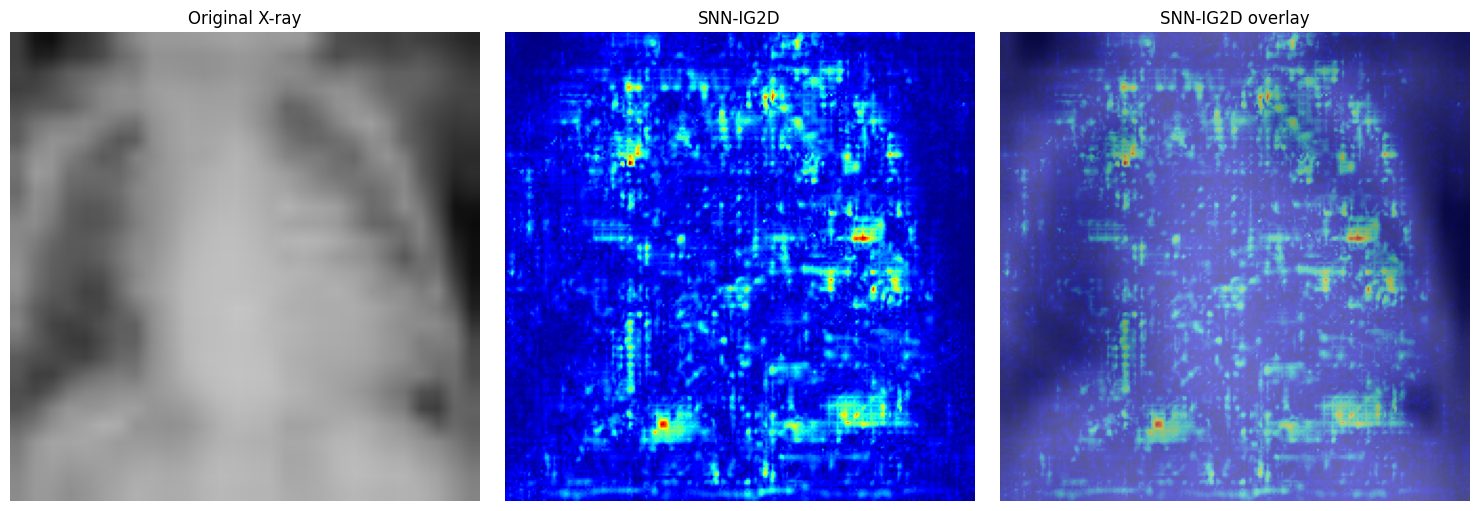

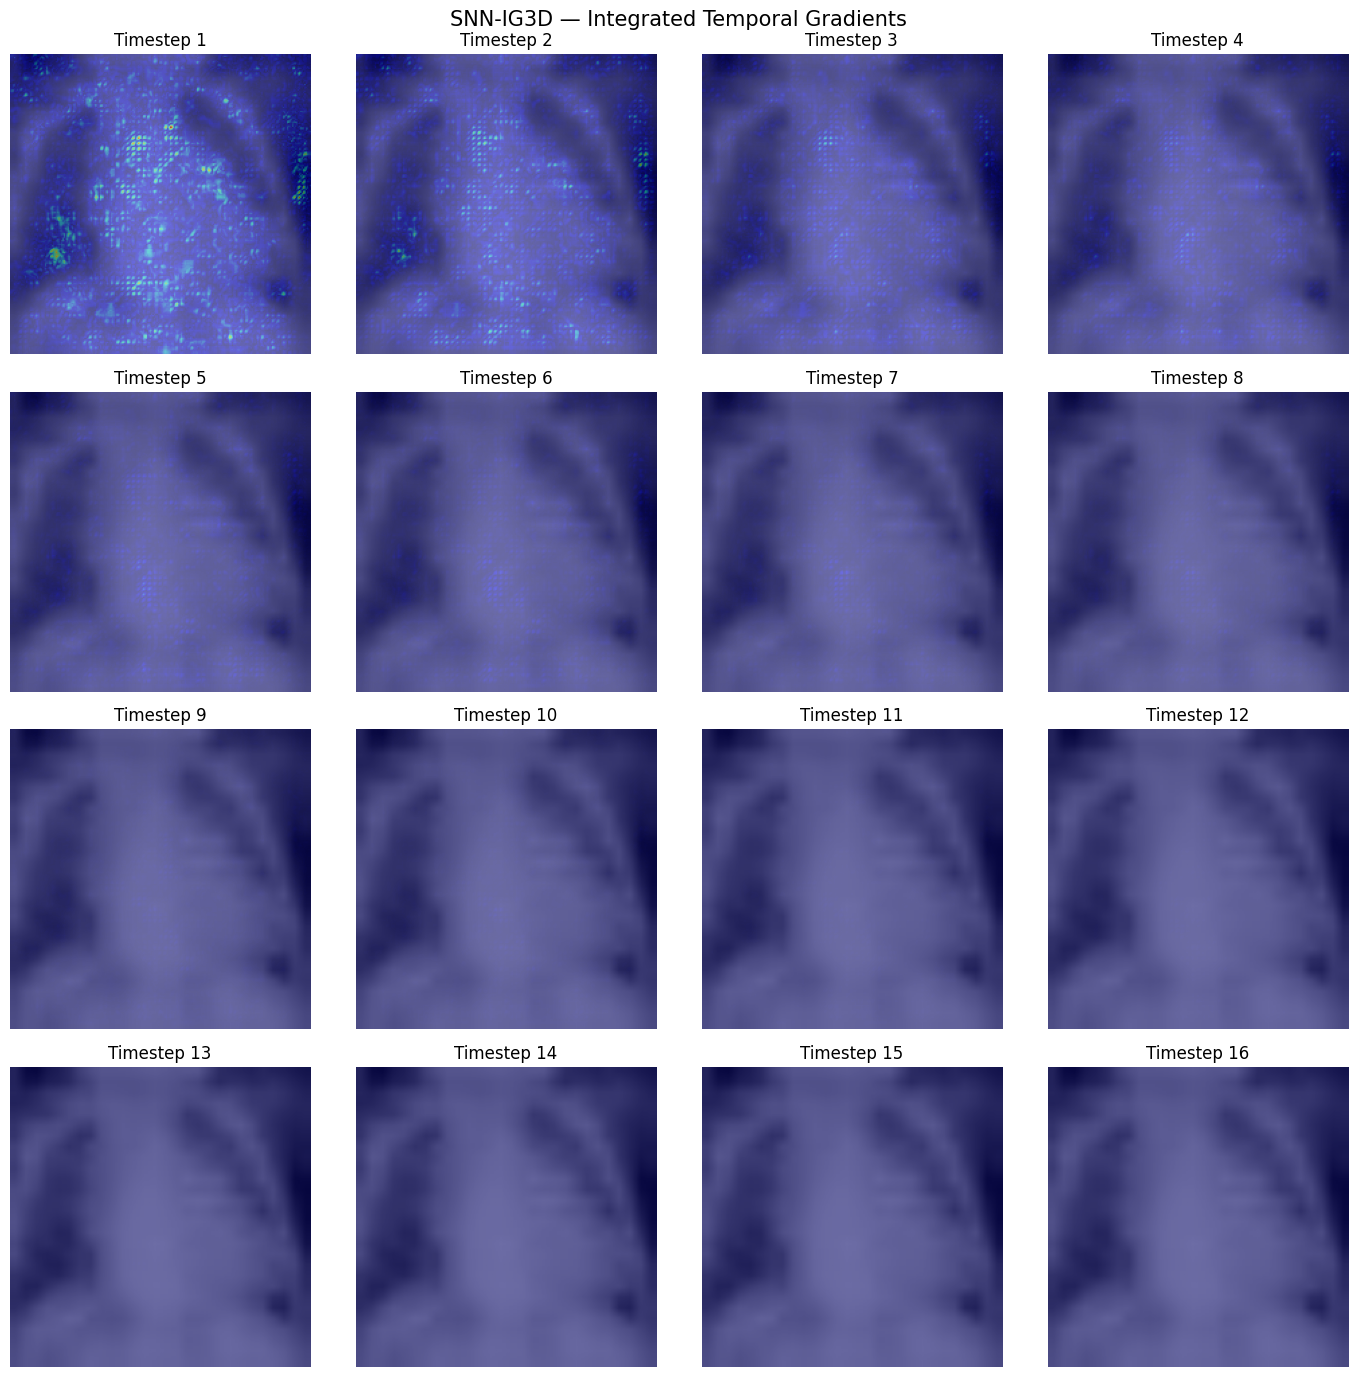

In [13]:

# ============================================================
# SECTION 8.3 — IG2D AND IG3D VISUALIZATION
# ============================================================

original_image = denormalize_xray(
    xai_samples["PNEUMONIA"]
)

ig2d_norm = normalize_map(
    ig2d_heatmap
)

fig, axes = plt.subplots(
    1, 3, figsize=(15, 5)
)

axes[0].imshow(original_image)
axes[0].set_title("Original X-ray")

axes[1].imshow(
    ig2d_norm,
    cmap="jet"
)
axes[1].set_title("SNN-IG2D")

axes[2].imshow(original_image)
axes[2].imshow(
    ig2d_norm,
    cmap="jet",
    alpha=0.45
)
axes[2].set_title("SNN-IG2D overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# IG3D temporal visualization
# Common scale across all 16 timesteps.
# ------------------------------------------------------------

ig3d_scale = (
    ig3d_heatmap.max().item() + 1e-8
)

fig, axes = plt.subplots(
    4, 4,
    figsize=(14, 14)
)

for t, ax in enumerate(axes.flat):

    temporal_map = (
        ig3d_heatmap[t].detach().cpu()
        / ig3d_scale
    )

    ax.imshow(original_image)

    ax.imshow(
        temporal_map,
        cmap="jet",
        alpha=0.45,
        vmin=0,
        vmax=1
    )

    ax.set_title(f"Timestep {t+1}")
    ax.axis("off")

plt.suptitle(
    "SNN-IG3D — Integrated Temporal Gradients",
    fontsize=15
)

plt.tight_layout()
plt.show()


In [14]:

# ============================================================
# SECTION 9 — IDENTIFY FINAL SPIKING FEATURE LAYER
# ============================================================

from spikingjelly.activation_based import functional
import torch
import torch.nn as nn

snn_model.eval()

# Find all spiking neurons
spiking_nodes = [
    (name, module)
    for name, module in snn_model.named_modules()
    if "IFNode" in type(module).__name__
    or "LIFNode" in type(module).__name__
]

print("Total spiking neurons:", len(spiking_nodes))

# Store lightweight output summaries, not full feature tensors.
spike_layer_stats = {}

hooks = []

def make_spike_diagnostic_hook(name):

    def hook(module, inputs, output):

        if not torch.is_tensor(output):
            return

        stats = spike_layer_stats.setdefault(
            name,
            {
                "calls": 0,
                "shape": tuple(output.shape),
                "min": float("inf"),
                "max": float("-inf"),
                "unique_values": set()
            }
        )

        stats["calls"] += 1

        detached = output.detach()

        stats["min"] = min(
            stats["min"],
            detached.min().item()
        )

        stats["max"] = max(
            stats["max"],
            detached.max().item()
        )

        if stats["calls"] == 1:
            stats["unique_values"] = set(
                torch.unique(detached).cpu().tolist()
            )

    return hook


for name, module in spiking_nodes:

    hooks.append(
        module.register_forward_hook(
            make_spike_diagnostic_hook(name)
        )
    )


# Run one independent image over 16 timesteps.
image = xai_samples["PNEUMONIA"]

functional.reset_net(snn_model)

try:

    with torch.no_grad():

        for t in range(XAI_TIMESTEPS):
            output = snn_model(image)

finally:

    for hook in hooks:
        hook.remove()

    functional.reset_net(snn_model)


# ------------------------------------------------------------
# Print spatial spiking feature layers
# ------------------------------------------------------------

spatial_spike_candidates = []

for name, stats in spike_layer_stats.items():

    shape = stats["shape"]

    if len(shape) == 4 and shape[-1] > 1 and shape[-2] > 1:

        spatial_spike_candidates.append(
            (name, stats)
        )

print("\nSPATIAL SPIKING LAYERS")
print("=" * 65)

for name, stats in spatial_spike_candidates:

    print("\nLayer:", name)
    print("Output shape:", stats["shape"])
    print("Calls:", stats["calls"])
    print("Minimum:", stats["min"])
    print("Maximum:", stats["max"])
    print(
        "Unique values:",
        sorted(stats["unique_values"])
    )


print("\nTOTAL SPATIAL SPIKING CANDIDATES:",
      len(spatial_spike_candidates))


Total spiking neurons: 121

SPATIAL SPIKING LAYERS

Layer: features.ltb_spiking_0.if_node
Output shape: (1, 64, 56, 56)
Calls: 16
Minimum: 0.0
Maximum: 1.0
Unique values: [0.0, 1.0]

Layer: features.denseblock1.denselayer1.ltb_spiking_0.if_node
Output shape: (1, 64, 56, 56)
Calls: 16
Minimum: 0.0
Maximum: 1.0
Unique values: [0.0, 1.0]

Layer: features.denseblock1.denselayer1.ltb_spiking_1.if_node
Output shape: (1, 128, 56, 56)
Calls: 16
Minimum: 0.0
Maximum: 1.0
Unique values: [0.0, 1.0]

Layer: features.denseblock1.denselayer2.ltb_spiking_0.if_node
Output shape: (1, 96, 56, 56)
Calls: 16
Minimum: 0.0
Maximum: 1.0
Unique values: [0.0, 1.0]

Layer: features.denseblock1.denselayer2.ltb_spiking_1.if_node
Output shape: (1, 128, 56, 56)
Calls: 16
Minimum: 0.0
Maximum: 1.0
Unique values: [0.0, 1.0]

Layer: features.denseblock1.denselayer3.ltb_spiking_0.if_node
Output shape: (1, 128, 56, 56)
Calls: 16
Minimum: 0.0
Maximum: 1.0
Unique values: [0.0, 1.0]

Layer: features.denseblock1.denselayer3

In [15]:

# ============================================================
# SECTION 10 — RECORD FINAL SPIKING FEATURE MAPS
# ============================================================

from spikingjelly.activation_based import functional
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

# Exact final spatial spiking layer identified in Section 9.
SAM_LAYER_NAME = "ltb_spiking_0.if_node"

SAM_GAMMA = 0.5
SAM_TRAIL = 5
SAM_INCLUDE_CURRENT = True

# Obtain the actual module.
SAM_LAYER = snn_model.get_submodule(SAM_LAYER_NAME)

print("Selected SAM layer:", SAM_LAYER_NAME)
print("Module type:", type(SAM_LAYER).__name__)

# ------------------------------------------------------------
# Record output from the selected spiking layer
# ------------------------------------------------------------

def record_final_spikes(image, timesteps=16):

    recorded_spikes = []

    def spike_hook(module, inputs, output):

        if not torch.is_tensor(output):
            raise TypeError(
                "Final spiking layer returned a non-tensor."
            )

        recorded_spikes.append(
            output.detach().clone()
        )

    hook = SAM_LAYER.register_forward_hook(spike_hook)

    snn_model.eval()
    functional.reset_net(snn_model)

    try:

        with torch.no_grad():

            for t in range(timesteps):
                snn_model(image)

    finally:

        hook.remove()
        functional.reset_net(snn_model)

    if len(recorded_spikes) != timesteps:

        raise RuntimeError(
            f"Expected {timesteps} recordings, "
            f"received {len(recorded_spikes)}."
        )

    # [T,1,C,7,7]
    feature_spikes = torch.stack(
        recorded_spikes,
        dim=0
    )

    return feature_spikes


# Record the PNEUMONIA sample.
# We explain the model's actual prediction, NORMAL.
sam_feature_spikes = record_final_spikes(
    xai_samples["PNEUMONIA"],
    timesteps=XAI_TIMESTEPS
)

print("\nSPIKE RECORDING RESULTS")
print("Recorded tensor shape:", tuple(sam_feature_spikes.shape))
print("Expected shape:", (16, 1, 1024, 7, 7))

print(
    "Unique spike values:",
    torch.unique(sam_feature_spikes).tolist()
)

print(
    "Binary spike check:",
    torch.all(
        (sam_feature_spikes == 0)
        | (sam_feature_spikes == 1)
    ).item()
)

assert sam_feature_spikes.shape == (16, 1, 1024, 7, 7)

assert torch.all(
    (sam_feature_spikes == 0)
    | (sam_feature_spikes == 1)
)

print("\nFinal spiking features recorded successfully.")


Selected SAM layer: ltb_spiking_0.if_node
Module type: HalfThresholdIFNode

SPIKE RECORDING RESULTS
Recorded tensor shape: (16, 1, 1024, 7, 7)
Expected shape: (16, 1, 1024, 7, 7)
Unique spike values: [0.0, 1.0]
Binary spike check: True

Final spiking features recorded successfully.


In [16]:

# ============================================================
# SECTION 10.1 — SAM AND INVERTED SAM
# Exact mentor spike-history formulation
# ============================================================

def sam_from_feature_spikes(
    feature_spk_rec,
    gamma=0.5,
    trail=5,
    include_current=True
):
    """
    feature_spk_rec: [T,1,C,H,W]

    Returns:
        SAM maps: [T,H,W]
    """

    if feature_spk_rec.ndim != 5:
        raise ValueError(
            "Expected [T,1,C,H,W] spike tensor."
        )

    # [T,1,C,H,W] -> [T,C,H,W]
    feat = feature_spk_rec[:, 0].float()

    T, C, H, W = feat.shape

    maps = []

    for t in range(T):

        if include_current:

            start = max(0, t - trail + 1)
            end = t + 1

        else:

            start = max(0, t - trail)
            end = t

        if end <= start:

            maps.append(
                torch.zeros(
                    (H, W),
                    device=feat.device
                )
            )

            continue

        taus = torch.arange(
            start,
            end,
            device=feat.device
        )

        weights = torch.exp(
            -gamma * (t - taus).float()
        ).view(-1, 1, 1, 1)

        # Weighted recent spike history.
        # NCS shape: [C,H,W]
        ncs = (
            feat[start:end] * weights
        ).sum(dim=0)

        # SAM map: current spikes multiplied
        # by weighted recent spike history.
        # Sum across channels.
        m_t = (
            ncs * feat[t]
        ).sum(dim=0)

        maps.append(m_t)

    return torch.stack(maps, dim=0)


# ------------------------------------------------------------
# Calculate SAM
# ------------------------------------------------------------

sam_small = sam_from_feature_spikes(
    sam_feature_spikes,
    gamma=SAM_GAMMA,
    trail=SAM_TRAIL,
    include_current=SAM_INCLUDE_CURRENT
)

# ------------------------------------------------------------
# Calculate Inverted SAM
# ------------------------------------------------------------

inverted_sam_small = -sam_small


# ------------------------------------------------------------
# Upsample 7x7 maps to original 224x224 image size
# Same bilinear interpolation used in mentor notebook.
# ------------------------------------------------------------

def upsample_maps(maps, size=(224, 224)):

    if maps.ndim == 2:
        maps = maps.unsqueeze(0)

    maps = maps.unsqueeze(1)

    maps_up = F.interpolate(
        maps,
        size=size,
        mode="bilinear",
        align_corners=False
    )

    return maps_up.squeeze(1)


sam_maps = upsample_maps(
    sam_small,
    size=(224, 224)
)

inverted_sam_maps = upsample_maps(
    inverted_sam_small,
    size=(224, 224)
)


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("SAM RESULTS")
print("Shape:", tuple(sam_maps.shape))
print("Minimum:", sam_maps.min().item())
print("Maximum:", sam_maps.max().item())
print("Mean:", sam_maps.mean().item())
print("All finite:", torch.isfinite(sam_maps).all().item())

print("\nINVERTED SAM RESULTS")
print("Shape:", tuple(inverted_sam_maps.shape))
print("Minimum:", inverted_sam_maps.min().item())
print("Maximum:", inverted_sam_maps.max().item())
print("Mean:", inverted_sam_maps.mean().item())
print(
    "All finite:",
    torch.isfinite(inverted_sam_maps).all().item()
)

assert sam_maps.shape == (16, 224, 224)
assert inverted_sam_maps.shape == (16, 224, 224)

assert torch.isfinite(sam_maps).all()
assert torch.isfinite(inverted_sam_maps).all()

print("\nSAM and Inverted SAM completed successfully.")


SAM RESULTS
Shape: (16, 224, 224)
Minimum: 203.561279296875
Maximum: 446.45050048828125
Mean: 329.7467346191406
All finite: True

INVERTED SAM RESULTS
Shape: (16, 224, 224)
Minimum: -446.45050048828125
Maximum: -203.561279296875
Mean: -329.7467346191406
All finite: True

SAM and Inverted SAM completed successfully.


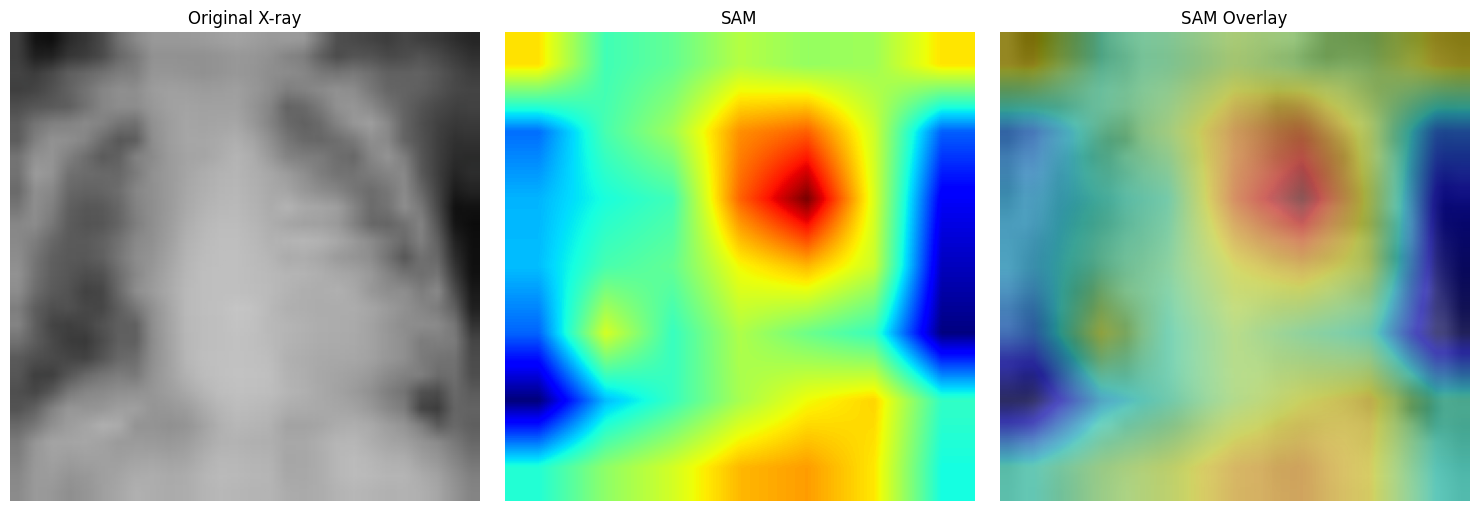

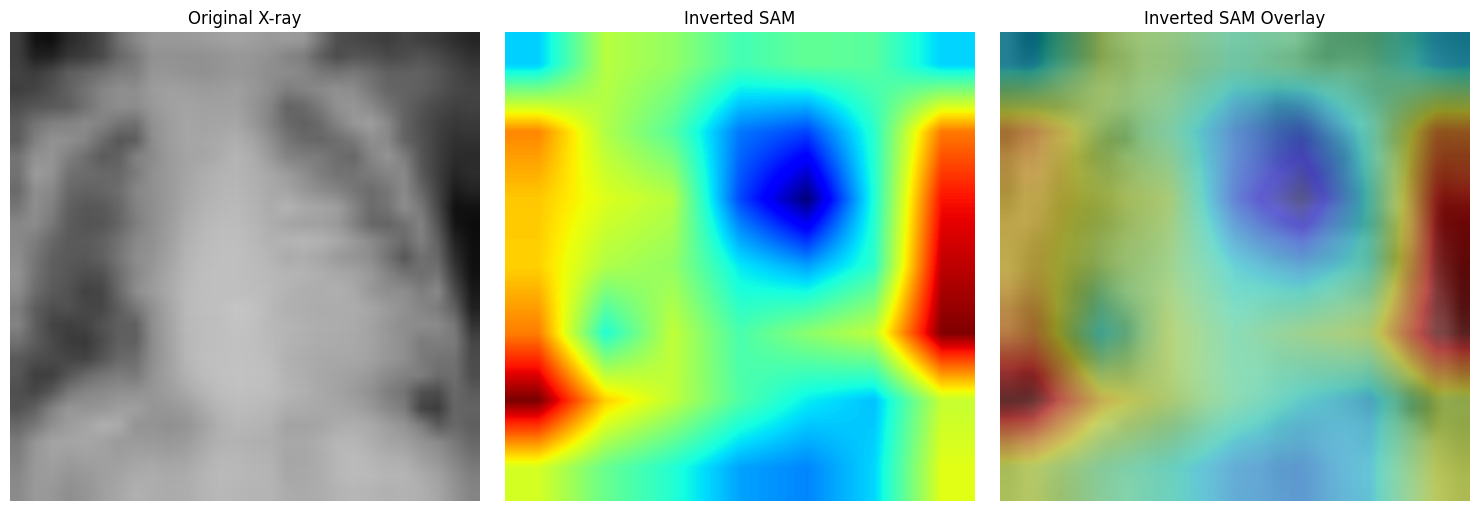

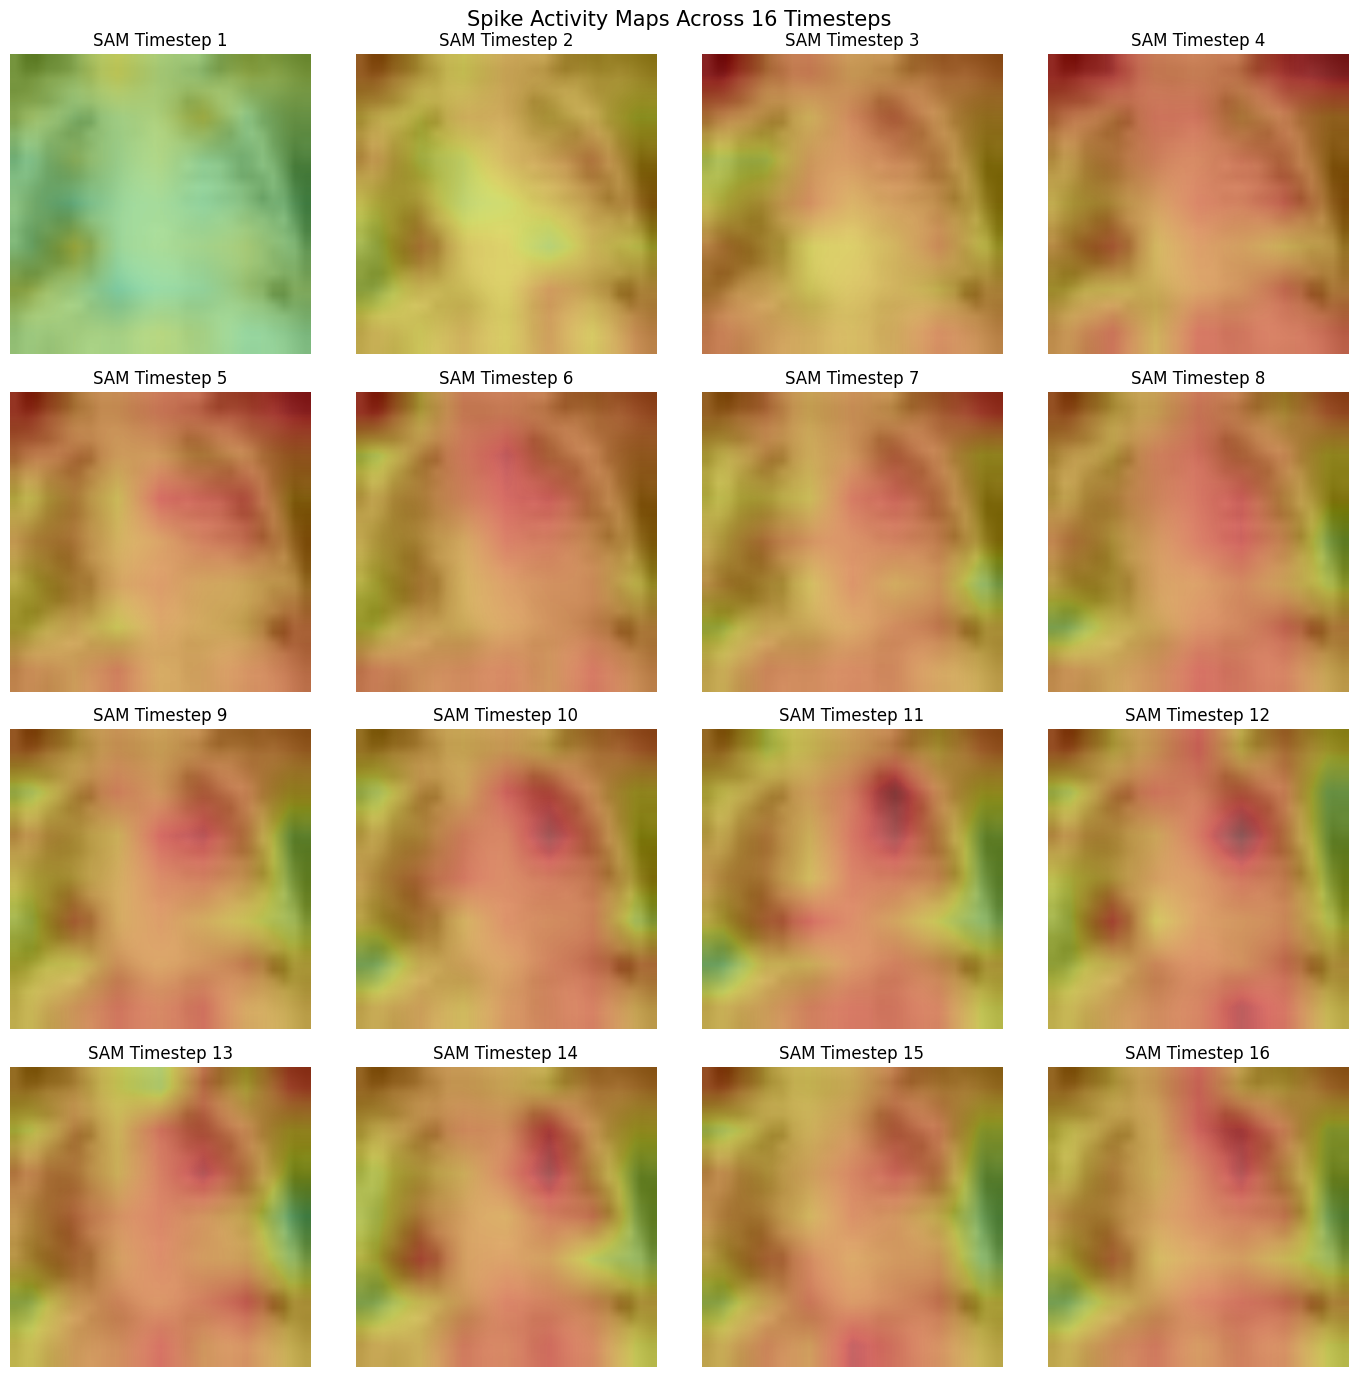

In [17]:

# ============================================================
# SECTION 10.2 — SAM VISUALIZATION
# ============================================================

original_image = denormalize_xray(
    xai_samples["PNEUMONIA"]
)

# Average over all 16 timesteps.
sam_2d = sam_maps.mean(dim=0)

inverted_sam_2d = inverted_sam_maps.mean(dim=0)


# Normalize for display only.
sam_display = normalize_map(sam_2d)

inverted_sam_display = normalize_map(
    inverted_sam_2d
)

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5)
)

axes[0].imshow(original_image)
axes[0].set_title("Original X-ray")

axes[1].imshow(
    sam_display,
    cmap="jet"
)
axes[1].set_title("SAM")

axes[2].imshow(original_image)
axes[2].imshow(
    sam_display,
    cmap="jet",
    alpha=0.45
)
axes[2].set_title("SAM Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Inverted SAM
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5)
)

axes[0].imshow(original_image)
axes[0].set_title("Original X-ray")

axes[1].imshow(
    inverted_sam_display,
    cmap="jet"
)
axes[1].set_title("Inverted SAM")

axes[2].imshow(original_image)
axes[2].imshow(
    inverted_sam_display,
    cmap="jet",
    alpha=0.45
)
axes[2].set_title("Inverted SAM Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Temporal SAM visualization
# ------------------------------------------------------------

fig, axes = plt.subplots(
    4, 4,
    figsize=(14, 14)
)

sam_global_max = sam_maps.max().item() + 1e-8

for t, ax in enumerate(axes.flat):

    temporal_map = (
        sam_maps[t].detach().cpu()
        / sam_global_max
    )

    ax.imshow(original_image)

    ax.imshow(
        temporal_map,
        cmap="jet",
        alpha=0.45,
        vmin=0,
        vmax=1
    )

    ax.set_title(f"SAM Timestep {t+1}")
    ax.axis("off")

plt.suptitle(
    "Spike Activity Maps Across 16 Timesteps",
    fontsize=15
)

plt.tight_layout()
plt.show()


In [18]:

# ============================================================
# SECTION 11 — SNN-CAM
# Spiking DenseNet121 implementation
# ============================================================

from spikingjelly.activation_based import functional
import torch
import torch.nn.functional as F


# Use the final spatial spiking layer identified earlier.
CAM_LAYER_NAME = "ltb_spiking_0.if_node"

CAM_LAYER = snn_model.get_submodule(
    CAM_LAYER_NAME
)


def snn_cam(
    model,
    image,
    timesteps=16,
    target_class=None,
    global_time_weight=True
):
    """
    SNN-CAM adapted from mentor's implementation.

    Feature activations:
        [T,C,h,w]

    Feature gradients:
        [T,C,h,w]

    Output:
        CAM maps [T,224,224]
    """

    model.eval()

    # Get the prediction before the gradient pass.
    pred_class, pneumonia_score = predict_for_xai(
        image,
        timesteps
    )

    if target_class is None:
        target_class = pred_class

    feature_activations = []

    def save_activation(module, inputs, output):

        if not torch.is_tensor(output):
            raise TypeError(
                "Expected a tensor from the CAM layer."
            )

        if torch.is_grad_enabled() and output.requires_grad:

            # Preserve gradient of this intermediate tensor.
            output.retain_grad()

            feature_activations.append(output)

        else:
            raise RuntimeError(
                "CAM activation does not require gradients."
            )

    hook = CAM_LAYER.register_forward_hook(
        save_activation
    )

    model.zero_grad(set_to_none=True)
    functional.reset_net(model)

    try:

        logits_per_step = []

        # ----------------------------------------------------
        # Forward through all timesteps
        # ----------------------------------------------------

        with torch.enable_grad():

            for t in range(timesteps):

                output = model(image)

                logits_per_step.append(
                    output.reshape(-1)[0]
                )

            logits = torch.stack(
                logits_per_step
            )

            # Binary signed target.
            # PNEUMONIA = +logit
            # NORMAL = -logit
            target_sign = (
                1.0 if target_class == 1 else -1.0
            )

            target_score = (
                target_sign * logits.sum()
            )

            # Backpropagate through all timesteps.
            target_score.backward()

        # ----------------------------------------------------
        # Collect activation and gradient records
        # ----------------------------------------------------

        if len(feature_activations) != timesteps:
            raise RuntimeError(
                f"Expected {timesteps} CAM activations, "
                f"received {len(feature_activations)}."
            )

        if any(
            activation.grad is None
            for activation in feature_activations
        ):
            raise RuntimeError(
                "Some CAM activation gradients are missing."
            )

        # Original activations: [T,1,C,h,w]
        acts = torch.stack([
            activation.detach()[0]
            for activation in feature_activations
        ], dim=0)

        # Original gradients: [T,1,C,h,w]
        grads = torch.stack([
            activation.grad.detach()[0]
            for activation in feature_activations
        ], dim=0)

        # Shapes become [T,C,h,w]
        print("CAM activations:", tuple(acts.shape))
        print("CAM gradients:", tuple(grads.shape))

        # ----------------------------------------------------
        # Calculate channel importance weights
        # ----------------------------------------------------

        if global_time_weight:

            # One importance weight per channel,
            # averaged across time and space.
            weights = grads.mean(
                dim=(0, 2, 3)
            )

            cam_small = (
                acts * weights.view(1, -1, 1, 1)
            ).sum(dim=1)

        else:

            # Separate importance weights per timestep.
            weights_t = grads.mean(
                dim=(2, 3)
            )

            cam_small = (
                acts * weights_t[:, :, None, None]
            ).sum(dim=1)

        # CAM retains positive evidence.
        cam_small = F.relu(cam_small)

        # ----------------------------------------------------
        # Upsample all temporal CAMs
        # ----------------------------------------------------

        cam_maps = upsample_maps(
            cam_small,
            size=(224, 224)
        )

        return {
            "heatmap": cam_maps.detach(),
            "small_heatmap": cam_small.detach(),
            "activations": acts.detach(),
            "gradients": grads.detach(),
            "channel_weights": weights.detach()
                if global_time_weight
                else weights_t.detach(),
            "predicted_class": pred_class,
            "target_class": target_class,
            "pneumonia_score": pneumonia_score,
            "global_time_weight": global_time_weight
        }

    finally:

        hook.remove()

        functional.reset_net(model)

        model.zero_grad(set_to_none=True)


print("SNN-CAM function created successfully.")
print("Selected layer:", CAM_LAYER_NAME)


SNN-CAM function created successfully.
Selected layer: ltb_spiking_0.if_node


In [19]:

# ============================================================
# SECTION 11.1 — GENERATE SNN-CAM
# ============================================================

cam_result = snn_cam(
    model=snn_model,
    image=xai_samples["PNEUMONIA"],
    timesteps=16,
    target_class=None,
    global_time_weight=True
)

cam_maps = cam_result["heatmap"]

print("\nSNN-CAM RESULTS")

print(
    "Actual sample label: PNEUMONIA"
)

print(
    "Model prediction:",
    class_names[cam_result["predicted_class"]]
)

print(
    "Explanation target:",
    class_names[cam_result["target_class"]]
)

print(
    "Pneumonia score:",
    cam_result["pneumonia_score"]
)

print("CAM shape:", tuple(cam_maps.shape))

print(
    "Small CAM shape:",
    tuple(cam_result["small_heatmap"].shape)
)

print(
    "Channel weights shape:",
    tuple(cam_result["channel_weights"].shape)
)

print("CAM minimum:", cam_maps.min().item())
print("CAM maximum:", cam_maps.max().item())

print(
    "All finite:",
    torch.isfinite(cam_maps).all().item()
)

assert cam_maps.shape == (16, 224, 224)

assert torch.isfinite(cam_maps).all()

print("\nSNN-CAM completed successfully.")


CAM activations: (16, 1024, 7, 7)
CAM gradients: (16, 1024, 7, 7)

SNN-CAM RESULTS
Actual sample label: PNEUMONIA
Model prediction: NORMAL
Explanation target: NORMAL
Pneumonia score: 0.9993041753768921
CAM shape: (16, 224, 224)
Small CAM shape: (16, 7, 7)
Channel weights shape: (1024,)
CAM minimum: 0.0
CAM maximum: 0.01986066810786724
All finite: True

SNN-CAM completed successfully.


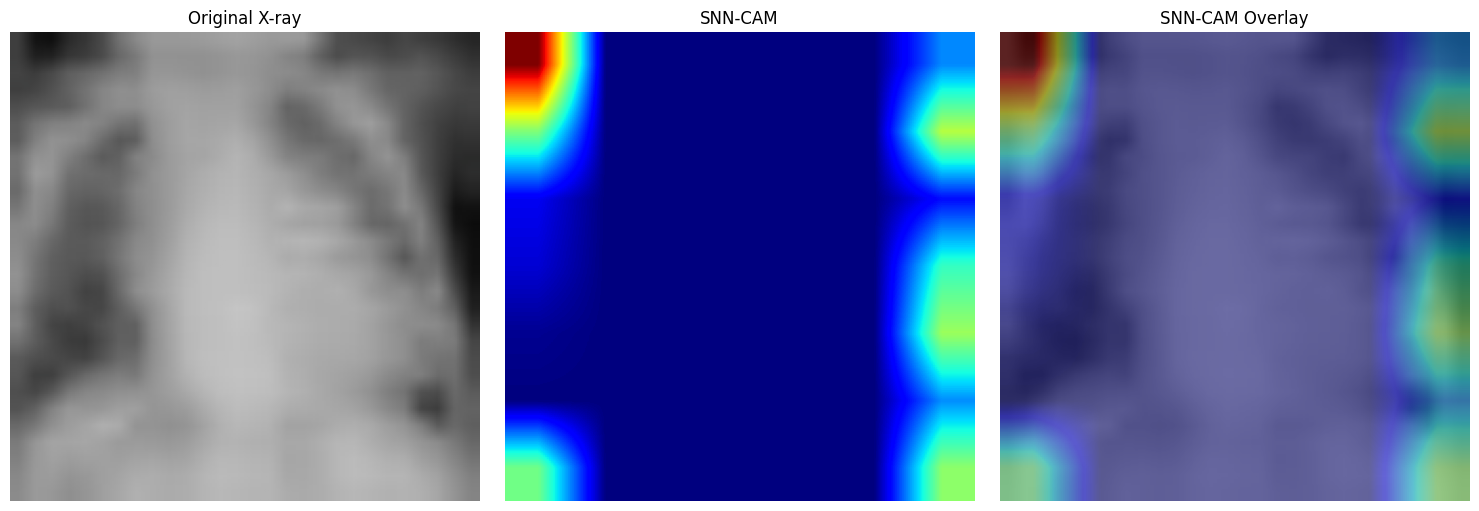

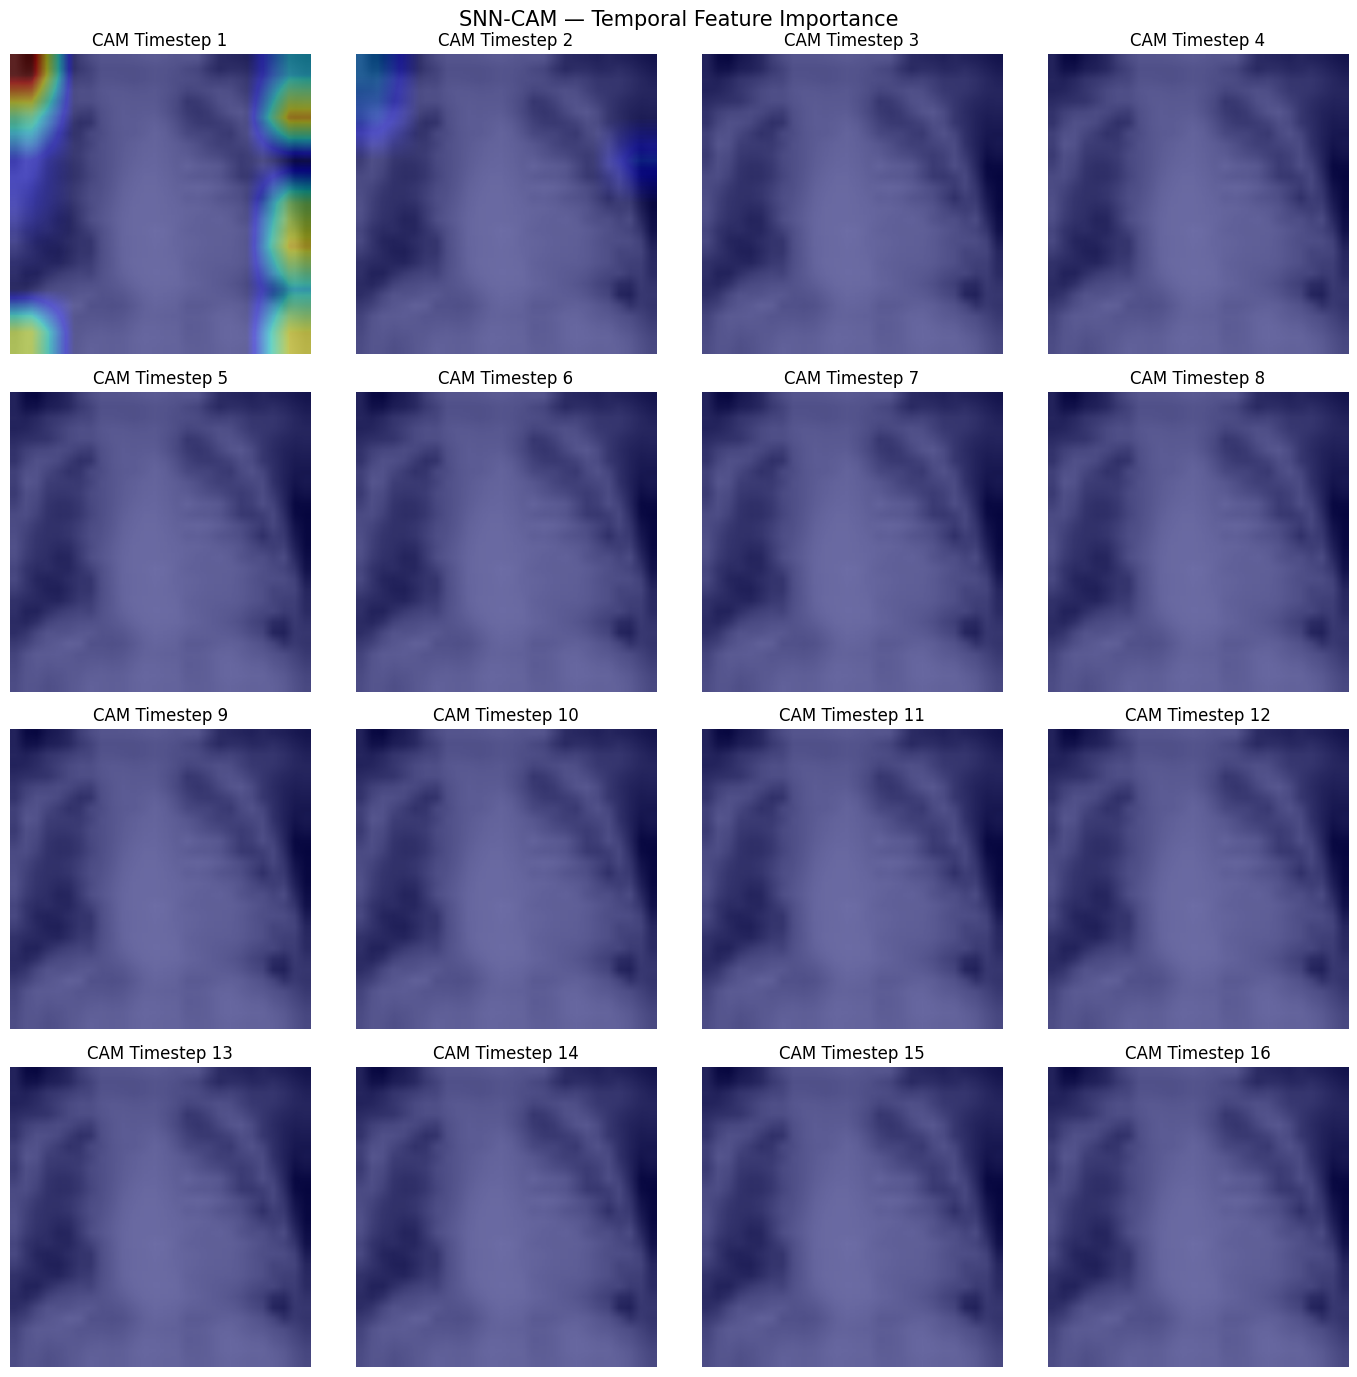

In [20]:

# ============================================================
# SECTION 11.2 — SNN-CAM VISUALIZATION
# ============================================================

original_image = denormalize_xray(
    xai_samples["PNEUMONIA"]
)

# Average CAM across all timesteps.
cam_2d = cam_maps.mean(dim=0)

cam_display = normalize_map(cam_2d)

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5)
)

axes[0].imshow(original_image)
axes[0].set_title("Original X-ray")

axes[1].imshow(
    cam_display,
    cmap="jet"
)
axes[1].set_title("SNN-CAM")

axes[2].imshow(original_image)
axes[2].imshow(
    cam_display,
    cmap="jet",
    alpha=0.45
)
axes[2].set_title("SNN-CAM Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Temporal CAM — 16 timesteps
# ------------------------------------------------------------

cam_global_max = cam_maps.max().item() + 1e-8

fig, axes = plt.subplots(
    4, 4,
    figsize=(14, 14)
)

for t, ax in enumerate(axes.flat):

    temporal_cam = (
        cam_maps[t].detach().cpu()
        / cam_global_max
    )

    ax.imshow(original_image)
    ax.imshow(
        temporal_cam,
        cmap="jet",
        alpha=0.45,
        vmin=0,
        vmax=1
    )

    ax.set_title(f"CAM Timestep {t+1}")
    ax.axis("off")

plt.suptitle(
    "SNN-CAM — Temporal Feature Importance",
    fontsize=15
)

plt.tight_layout()
plt.show()


In [21]:

# ============================================================
# SECTION 12 — PIXEL DELETION EVALUATION
# Adapted from mentor's original implementation
# ============================================================

import torch
import numpy as np
import matplotlib.pyplot as plt

from spikingjelly.activation_based import functional


# ------------------------------------------------------------
# 1. Generate ImageNet-normalized black baseline
# ------------------------------------------------------------

def make_deletion_baseline(image):

    mean = torch.tensor(
        IMAGENET_MEAN,
        device=image.device
    ).view(1, 3, 1, 1)

    std = torch.tensor(
        IMAGENET_STD,
        device=image.device
    ).view(1, 3, 1, 1)

    raw_black = torch.zeros_like(image)

    return (raw_black - mean) / std


# ------------------------------------------------------------
# 2. Normalize heatmap for pixel ranking
# ------------------------------------------------------------

def normalize_deletion_heatmap(heatmap, eps=1e-8):

    heatmap = heatmap.detach().float().cpu()

    heatmap = heatmap - heatmap.min()

    heatmap = heatmap / (
        heatmap.max() + eps
    )

    return heatmap


# ------------------------------------------------------------
# 3. Perturb image using top-ranked pixels
# ------------------------------------------------------------

def perturb_pixels_by_heatmap(
    image,
    heatmap,
    fractions,
    baseline_mode="black",
    random_order=None
):

    baseline = make_deletion_baseline(image)

    H, W = heatmap.shape

    if random_order is None:

        pixel_order = torch.argsort(
            heatmap.flatten(),
            descending=True
        )

    else:
        pixel_order = random_order

    perturbed_images = []

    for fraction in fractions:

        x = image.clone()

        k = int(fraction * H * W)

        if k > 0:

            indices = pixel_order[:k]

            rows = indices // W
            cols = indices % W

            x[:, :, rows, cols] = (
                baseline[:, :, rows, cols]
            )

        perturbed_images.append(x)

    return torch.cat(
        perturbed_images,
        dim=0
    )


# ------------------------------------------------------------
# 4. Calculate classification margin for a batch
# ------------------------------------------------------------

@torch.no_grad()
def score_target_class_batch(
    model,
    images,
    target_class,
    timesteps=16
):

    functional.reset_net(model)

    try:

        step_outputs = []

        for t in range(timesteps):

            output = model(images)

            step_outputs.append(
                output.reshape(images.shape[0], -1)[:, 0]
            )

        average_logits = torch.stack(
            step_outputs,
            dim=0
        ).mean(dim=0)

        threshold_tensor = torch.tensor(
            XAI_THRESHOLD,
            device=images.device
        )

        threshold_logit = torch.log(
            threshold_tensor / (1.0 - threshold_tensor)
        )

        if target_class == 1:

            # PNEUMONIA margin
            target_margin = (
                average_logits - threshold_logit
            )

        else:

            # NORMAL margin
            target_margin = (
                threshold_logit - average_logits
            )

        pneumonia_scores = torch.sigmoid(
            average_logits
        )

        return (
            target_margin.detach().cpu(),
            pneumonia_scores.detach().cpu()
        )

    finally:

        functional.reset_net(model)


print("Pixel deletion functions created.")


Pixel deletion functions created.


In [22]:

# ============================================================
# SECTION 12.1 — PREPARE EXPLANATION MAPS
# ============================================================

# Same PNEUMONIA image used for the earlier XAI methods.
deletion_image = xai_samples["PNEUMONIA"]

# Determine predicted class using the T16 threshold.
deletion_pred_class, deletion_score = predict_for_xai(
    deletion_image,
    timesteps=16
)

deletion_target_class = deletion_pred_class

print("Actual sample label: PNEUMONIA")

print(
    "Model prediction:",
    class_names[deletion_pred_class]
)

print("Pneumonia score:", deletion_score)

print("Explanation target:",
      class_names[deletion_target_class])


# ------------------------------------------------------------
# Create common 2D heatmaps by averaging temporal maps
# ------------------------------------------------------------

method_heatmaps = {

    "SNN-Grad2D": grad2d.detach(),

    "SNN-IG2D": ig2d_heatmap.detach(),

    "SAM-last": sam_maps.mean(dim=0).detach(),

    "I-SAM-last": inverted_sam_maps.mean(dim=0).detach(),

    "SNN-CAM-last": cam_maps.mean(dim=0).detach()
}


# Normalize all maps for ranking.
normalized_method_heatmaps = {}

for name, heatmap in method_heatmaps.items():

    normalized = normalize_deletion_heatmap(
        heatmap
    )

    assert normalized.shape == (224, 224)

    assert torch.isfinite(normalized).all()

    normalized_method_heatmaps[name] = normalized


print("\nMETHOD HEATMAPS PREPARED")

for name, heatmap in normalized_method_heatmaps.items():

    print(
        name,
        "| Shape:", tuple(heatmap.shape),
        "| Min:", heatmap.min().item(),
        "| Max:", heatmap.max().item()
    )


# ------------------------------------------------------------
# Deletion fractions: 0% to 100%
# ------------------------------------------------------------

deletion_fractions = np.linspace(
    0.0, 1.0, 11
)

# Reproducible random control ordering.
random_generator = torch.Generator().manual_seed(42)

random_order = torch.randperm(
    224 * 224,
    generator=random_generator
)

print("\nDeletion fractions (%):")
print(deletion_fractions * 100)


Actual sample label: PNEUMONIA
Model prediction: NORMAL
Pneumonia score: 0.9993041753768921
Explanation target: NORMAL

METHOD HEATMAPS PREPARED
SNN-Grad2D | Shape: (224, 224) | Min: 0.0 | Max: 1.0
SNN-IG2D | Shape: (224, 224) | Min: 0.0 | Max: 1.0
SAM-last | Shape: (224, 224) | Min: 0.0 | Max: 1.0
I-SAM-last | Shape: (224, 224) | Min: 0.0 | Max: 1.0
SNN-CAM-last | Shape: (224, 224) | Min: 0.0 | Max: 0.9999935626983643

Deletion fractions (%):
[  0.  10.  20.  30.  40.  50.  60.  70.  80.  90. 100.]


In [23]:

# ============================================================
# SECTION 12.2 — RUN PIXEL DELETION EXPERIMENT
# ============================================================

import time

deletion_results = {}

all_methods = dict(
    normalized_method_heatmaps
)

# Random deletion baseline
all_methods["Random"] = None

for method_name, heatmap in all_methods.items():

    print("\n" + "=" * 55)
    print("METHOD:", method_name)
    print("=" * 55)

    start_time = time.perf_counter()

    if method_name == "Random":

        perturbed_batch = perturb_pixels_by_heatmap(
            image=deletion_image,
            heatmap=torch.zeros(224, 224),
            fractions=deletion_fractions,
            random_order=random_order
        )

    else:

        perturbed_batch = perturb_pixels_by_heatmap(
            image=deletion_image,
            heatmap=heatmap,
            fractions=deletion_fractions
        )

    print(
        "Perturbed batch:",
        tuple(perturbed_batch.shape)
    )

    # Score all 11 perturbations.
    margins, pneumonia_scores = score_target_class_batch(
        model=snn_model,
        images=perturbed_batch,
        target_class=deletion_target_class,
        timesteps=16
    )

    elapsed = time.perf_counter() - start_time

    deletion_results[method_name] = {
        "margins": margins.numpy(),
        "pneumonia_scores": pneumonia_scores.numpy(),
        "time_seconds": elapsed
    }

    print(
        "Target classification margins:",
        np.round(margins.numpy(), 5)
    )

    print(
        "Pneumonia scores:",
        np.round(pneumonia_scores.numpy(), 6)
    )

    print("Elapsed seconds:", round(elapsed, 2))


print("\nALL PIXEL DELETION EXPERIMENTS COMPLETED.")



METHOD: SNN-Grad2D
Perturbed batch: (11, 3, 224, 224)
Target classification margins: [ 2.13161 -1.91663 -2.13042 -1.69285 -1.44032 -1.63646 -1.68955 -1.32301
 -1.77751 -2.13936  1.52164]
Pneumonia scores: [0.999304 0.999988 0.99999  0.999985 0.99998  0.999984 0.999985 0.999978
 0.999986 0.99999  0.999622]
Elapsed seconds: 22.65

METHOD: SNN-IG2D
Perturbed batch: (11, 3, 224, 224)
Target classification margins: [ 2.13161 -0.22277 -1.14121 -1.05008 -1.30062 -1.0073  -0.47101 -0.7576
 -1.64802 -3.00291  1.52164]
Pneumonia scores: [0.999304 0.999934 0.999974 0.999971 0.999978 0.99997  0.999948 0.999961
 0.999984 0.999996 0.999622]
Elapsed seconds: 24.33

METHOD: SAM-last
Perturbed batch: (11, 3, 224, 224)
Target classification margins: [2.13161 2.32303 3.44479 3.87996 4.4182  4.41323 3.8528  3.8329  3.31482
 2.88608 1.52164]
Pneumonia scores: [0.999304 0.999157 0.997418 0.996015 0.993194 0.993227 0.996122 0.996198
 0.997732 0.998521 0.999622]
Elapsed seconds: 22.7

METHOD: I-SAM-last
Pert

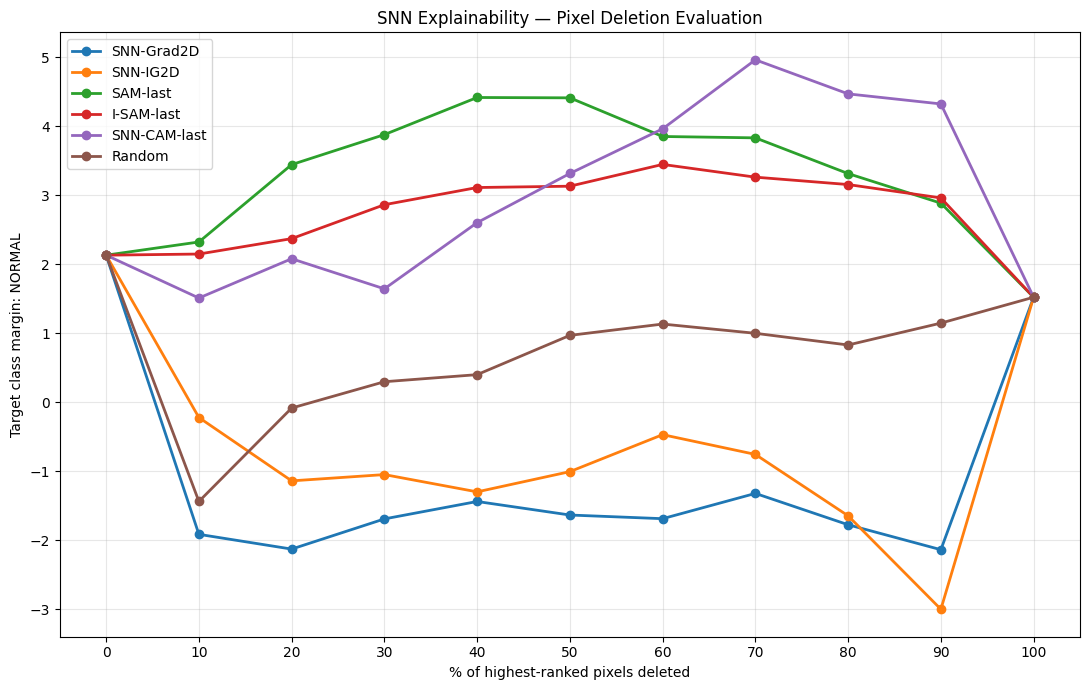

Saved: snn_pixel_deletion_comparison.png


In [24]:

# ============================================================
# SECTION 12.3 — PIXEL DELETION COMPARISON
# ============================================================

plt.figure(figsize=(11, 7))

for name, result in deletion_results.items():

    plt.plot(
        deletion_fractions * 100,
        result["margins"],
        marker="o",
        linewidth=2,
        label=name
    )

plt.xlabel(
    "% of highest-ranked pixels deleted"
)

plt.ylabel(
    f"Target class margin: {class_names[deletion_target_class]}"
)

plt.title(
    "SNN Explainability — Pixel Deletion Evaluation"
)

plt.xticks(
    np.arange(0, 101, 10)
)

plt.grid(True, alpha=0.3)

plt.legend()

plt.tight_layout()

plt.savefig(
    "snn_pixel_deletion_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved: snn_pixel_deletion_comparison.png"
)


In [25]:

# ============================================================
# SECTION 12.4 — DELETION AUC
# ============================================================

from sklearn.metrics import auc

deletion_auc = {}

for name, result in deletion_results.items():

    curve = result["margins"]

    deletion_auc[name] = auc(
        deletion_fractions,
        curve
    )

print("\nPIXEL DELETION AUC RESULTS")
print("=" * 50)

for name, value in deletion_auc.items():

    print(
        f"{name:18s}: {value:.6f}"
    )

print("\nInterpretation:")
print(
    "Lower deletion AUC means the target-class margin "
    "decreases faster as the highest-ranked pixels "
    "are removed."
)



PIXEL DELETION AUC RESULTS
SNN-Grad2D        : -1.391948
SNN-IG2D          : -0.877490
SAM-last          : 3.419245
I-SAM-last        : 2.828264
SNN-CAM-last      : 3.070369
Random            : 0.607337

Interpretation:
Lower deletion AUC means the target-class margin decreases faster as the highest-ranked pixels are removed.


In [26]:

# ============================================================
# SECTION 12.5 — SECOND SAMPLE PIXEL DELETION
# Correctly classified NORMAL image
# ============================================================

normal_xai_image = xai_samples["NORMAL"]

# ------------------------------------------------------------
# 1. Obtain actual prediction
# ------------------------------------------------------------

normal_target, normal_score = predict_for_xai(
    normal_xai_image,
    timesteps=16
)

print("Actual sample label: NORMAL")
print("Model prediction:", class_names[normal_target])
print("Pneumonia score:", normal_score)

assert normal_target == 0, (
    "The NORMAL sample was not classified as NORMAL. "
    "Check the prediction before continuing."
)


# ------------------------------------------------------------
# 2. Generate Grad2D
# ------------------------------------------------------------

normal_grad_result = snn_grad2d(
    snn_model,
    normal_xai_image,
    timesteps=16,
    target_class=normal_target
)

normal_grad2d = normal_grad_result[0]


# ------------------------------------------------------------
# 3. Generate IG2D
# ------------------------------------------------------------

normal_ig_result = snn_ig2d(
    snn_model,
    normal_xai_image,
    target_class=normal_target,
    n_steps=50,
    baseline_mode="black"
)

normal_ig2d = normal_ig_result["heatmap"]


# ------------------------------------------------------------
# 4. Generate SAM and Inverted SAM
# ------------------------------------------------------------

normal_spikes = record_final_spikes(
    normal_xai_image,
    timesteps=16
)

normal_sam_small = sam_from_feature_spikes(
    normal_spikes,
    gamma=0.5,
    trail=5,
    include_current=True
)

normal_sam = upsample_maps(
    normal_sam_small,
    size=(224, 224)
)

normal_inverted_sam = -normal_sam


# ------------------------------------------------------------
# 5. Generate SNN-CAM
# ------------------------------------------------------------

normal_cam_result = snn_cam(
    snn_model,
    normal_xai_image,
    timesteps=16,
    target_class=normal_target,
    global_time_weight=True
)

normal_cam = normal_cam_result["heatmap"].mean(dim=0)


# ------------------------------------------------------------
# 6. Prepare all 2D maps
# ------------------------------------------------------------

normal_method_maps = {

    "SNN-Grad2D": normal_grad2d,

    "SNN-IG2D": normal_ig2d,

    "SAM": normal_sam.mean(dim=0),

    "Inverted SAM": normal_inverted_sam.mean(dim=0),

    "SNN-CAM": normal_cam
}

normal_method_maps = {
    name: normalize_deletion_heatmap(heatmap)
    for name, heatmap in normal_method_maps.items()
}

print("\nNORMAL SAMPLE HEATMAPS READY")

for name, heatmap in normal_method_maps.items():
    print(name, tuple(heatmap.shape))


# ------------------------------------------------------------
# 7. Run pixel deletion
# ------------------------------------------------------------

normal_deletion_results = {}

for method_name, heatmap in normal_method_maps.items():

    print("\nRunning:", method_name)

    perturbed_batch = perturb_pixels_by_heatmap(
        normal_xai_image,
        heatmap,
        deletion_fractions
    )

    margins, scores = score_target_class_batch(
        snn_model,
        perturbed_batch,
        target_class=normal_target,
        timesteps=16
    )

    normal_deletion_results[method_name] = {
        "margins": margins.numpy(),
        "pneumonia_scores": scores.numpy()
    }

    print(
        "Margins:",
        np.round(margins.numpy(), 5)
    )


# ------------------------------------------------------------
# 8. Random deletion baseline
# ------------------------------------------------------------

normal_random_batch = perturb_pixels_by_heatmap(
    normal_xai_image,
    torch.zeros(224, 224),
    deletion_fractions,
    random_order=random_order
)

normal_random_margins, normal_random_scores = (
    score_target_class_batch(
        snn_model,
        normal_random_batch,
        target_class=normal_target,
        timesteps=16
    )
)

normal_deletion_results["Random"] = {
    "margins": normal_random_margins.numpy(),
    "pneumonia_scores": normal_random_scores.numpy()
}


# ------------------------------------------------------------
# 9. Calculate deletion AUC
# ------------------------------------------------------------

normal_deletion_auc = {}

for name, result in normal_deletion_results.items():

    normal_deletion_auc[name] = auc(
        deletion_fractions,
        result["margins"]
    )

print("\nNORMAL SAMPLE DELETION AUC")
print("=" * 50)

for name, value in normal_deletion_auc.items():
    print(f"{name:18s}: {value:.6f}")


Actual sample label: NORMAL
Model prediction: NORMAL
Pneumonia score: 0.9993658661842346


SNN-IG2D:   0%|          | 0/50 [00:00<?, ?it/s]

CAM activations: (16, 1024, 7, 7)
CAM gradients: (16, 1024, 7, 7)

NORMAL SAMPLE HEATMAPS READY
SNN-Grad2D (224, 224)
SNN-IG2D (224, 224)
SAM (224, 224)
Inverted SAM (224, 224)
SNN-CAM (224, 224)

Running: SNN-Grad2D
Margins: [ 2.03867 -1.25592 -2.41199 -2.42109 -2.01558 -1.89309 -0.84642 -1.05798
 -1.2436  -1.80588  1.52164]

Running: SNN-IG2D
Margins: [ 2.03867 -0.34481 -1.00212 -1.06968 -0.78031 -1.00566 -0.87703 -0.45176
 -1.03237 -1.55672  1.52164]

Running: SAM
Margins: [2.03867 2.54262 2.67384 3.81576 4.02561 4.8333  4.89462 5.26517 4.84061
 3.61317 1.52164]

Running: Inverted SAM
Margins: [2.03867 1.13234 2.08006 2.68977 3.44677 3.60396 4.12315 4.30035 3.37333
 3.10352 1.52164]

Running: SNN-CAM
Margins: [2.03867 1.503   2.57117 3.68421 3.617   3.58909 3.61482 4.24767 3.40667
 2.89096 1.52164]

NORMAL SAMPLE DELETION AUC
SNN-Grad2D        : -1.317139
SNN-IG2D          : -0.634030
SAM               : 3.828485
Inverted SAM      : 2.963340
SNN-CAM           : 3.090477
Random      

In [32]:

# ============================================================
# SECTION 12.6 — COMBINED DELETION AUC COMPARISON
# Corrected dictionary key mapping
# ============================================================

comparison_pairs = [
    ("SNN-Grad2D", "SNN-Grad2D", "SNN-Grad2D"),
    ("SNN-IG2D", "SNN-IG2D", "SNN-IG2D"),
    ("SAM", "SAM-last", "SAM"),
    ("Inverted SAM", "I-SAM-last", "Inverted SAM"),
    ("SNN-CAM", "SNN-CAM-last", "SNN-CAM"),
    ("Random", "Random", "Random")
]

print("\nCOMBINED DELETION AUC COMPARISON")
print("=" * 70)

print(
    f"{'Method':20s}"
    f"{'Pneumonia image':>20s}"
    f"{'Normal image':>20s}"
)

combined_auc_results = {}

for display_name, pneumonia_key, normal_key in comparison_pairs:

    pneumonia_value = deletion_auc[pneumonia_key]
    normal_value = normal_deletion_auc[normal_key]

    combined_auc_results[display_name] = {
        "Pneumonia": float(pneumonia_value),
        "Normal": float(normal_value)
    }

    print(
        f"{display_name:20s}"
        f"{pneumonia_value:>20.5f}"
        f"{normal_value:>20.5f}"
    )

print("\nComparison completed successfully.")



COMBINED DELETION AUC COMPARISON
Method                   Pneumonia image        Normal image
SNN-Grad2D                      -1.39195            -1.31714
SNN-IG2D                        -0.87749            -0.63403
SAM                              3.41924             3.82849
Inverted SAM                     2.82826             2.96334
SNN-CAM                          3.07037             3.09048
Random                           0.60734             0.94612

Comparison completed successfully.


In [33]:

# ============================================================
# SECTION 13 — SAVE XAI RESULTS AND EVALUATION
# Corrected method-name mapping
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Create directories
# ------------------------------------------------------------

XAI_RESULTS_DIR = PROJECT_ROOT / "explainability" / "results"

HEATMAP_DIR = XAI_RESULTS_DIR / "heatmaps"
TEMPORAL_DIR = XAI_RESULTS_DIR / "temporal"
PLOT_DIR = XAI_RESULTS_DIR / "plots"

for folder in [HEATMAP_DIR, TEMPORAL_DIR, PLOT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. Correct method-name mapping
# ------------------------------------------------------------

method_mapping = [
    ("SNN-Grad2D", "SNN-Grad2D", "SNN-Grad2D"),
    ("SNN-IG2D", "SNN-IG2D", "SNN-IG2D"),
    ("SAM", "SAM-last", "SAM"),
    ("Inverted SAM", "I-SAM-last", "Inverted SAM"),
    ("SNN-CAM", "SNN-CAM-last", "SNN-CAM"),
    ("Random", "Random", "Random")
]

combined_rows = []

for display_name, pneumonia_key, normal_key in method_mapping:

    combined_rows.append({
        "Method": display_name,
        "Pneumonia_Sample_AUC": float(
            deletion_auc[pneumonia_key]
        ),
        "Normal_Sample_AUC": float(
            normal_deletion_auc[normal_key]
        )
    })

combined_df = pd.DataFrame(combined_rows)

print("\nCOMBINED PIXEL DELETION RESULTS")
print(combined_df.to_string(index=False))

combined_df.to_csv(
    XAI_RESULTS_DIR / "pixel_deletion_comparison.csv",
    index=False
)


# ------------------------------------------------------------
# 3. Save 2D heatmaps
# ------------------------------------------------------------

pneumonia_heatmaps = {
    name: normalize_map(value)
    for name, value in method_heatmaps.items()
}

normal_heatmaps = {
    name: normalize_map(value)
    for name, value in normal_method_maps.items()
}

for sample_name, heatmaps in [
    ("pneumonia", pneumonia_heatmaps),
    ("normal", normal_heatmaps)
]:

    for method_name, heatmap in heatmaps.items():

        filename = (
            method_name.lower()
            .replace("-", "_")
            .replace(" ", "_")
        )

        array = heatmap.detach().cpu().numpy()

        np.save(
            HEATMAP_DIR / f"{sample_name}_{filename}.npy",
            array
        )

        plt.imsave(
            HEATMAP_DIR / f"{sample_name}_{filename}.png",
            array,
            cmap="jet"
        )


# ------------------------------------------------------------
# 4. Save temporal explanations
# ------------------------------------------------------------

temporal_explanations = {
    "grad3d": grad3d,
    "ig3d": ig3d_heatmap,
    "sam": sam_maps,
    "inverted_sam": inverted_sam_maps,
    "snn_cam": cam_maps
}

for name, tensor in temporal_explanations.items():

    np.save(
        TEMPORAL_DIR / f"pneumonia_{name}.npy",
        tensor.detach().cpu().numpy()
    )


# ------------------------------------------------------------
# 5. Save deletion curves
# ------------------------------------------------------------

for sample_name, results in [
    ("pneumonia", deletion_results),
    ("normal", normal_deletion_results)
]:

    plt.figure(figsize=(10, 6))

    for method_name, result in results.items():

        plt.plot(
            deletion_fractions * 100,
            result["margins"],
            marker="o",
            label=method_name
        )

    plt.xlabel("Percentage of pixels deleted")
    plt.ylabel("Target class margin")

    plt.title(
        f"Pixel Deletion — {sample_name.upper()} sample"
    )

    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        PLOT_DIR / f"{sample_name}_deletion_curve.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()


# ------------------------------------------------------------
# 6. Save experiment metadata
# ------------------------------------------------------------

experiment_metadata = {
    "model": "DenseNet121 SpikingJelly SNN",
    "timesteps": 16,
    "threshold": XAI_THRESHOLD,
    "sam_gamma": SAM_GAMMA,
    "sam_trail": SAM_TRAIL,
    "sam_include_current": SAM_INCLUDE_CURRENT,
    "integrated_gradients_steps": 50,
    "target_classes": {
        "normal": 0,
        "pneumonia": 1
    },
    "methods": [
        "SNN-Grad2D",
        "SNN-Grad3D",
        "SNN-IG2D",
        "SNN-IG3D",
        "SAM",
        "Inverted SAM",
        "SNN-CAM",
        "Pixel Deletion"
    ],
    "sample_scope": 2,
    "clinical_validation": False
}

with open(
    XAI_RESULTS_DIR / "xai_metadata.json",
    "w"
) as f:

    json.dump(
        experiment_metadata,
        f,
        indent=4
    )


# ------------------------------------------------------------
# 7. Save combined results as JSON
# ------------------------------------------------------------

with open(
    XAI_RESULTS_DIR / "pixel_deletion_comparison.json",
    "w"
) as f:

    json.dump(
        combined_rows,
        f,
        indent=4
    )


print("\nXAI RESULTS SAVED SUCCESSFULLY")

for path in sorted(XAI_RESULTS_DIR.rglob("*")):

    if path.is_file():
        print(path.relative_to(PROJECT_ROOT))



COMBINED PIXEL DELETION RESULTS
      Method  Pneumonia_Sample_AUC  Normal_Sample_AUC
  SNN-Grad2D             -1.391948          -1.317139
    SNN-IG2D             -0.877490          -0.634030
         SAM              3.419245           3.828485
Inverted SAM              2.828264           2.963340
     SNN-CAM              3.070369           3.090477
      Random              0.607337           0.946124

XAI RESULTS SAVED SUCCESSFULLY
explainability\results\heatmaps\normal_inverted_sam.npy
explainability\results\heatmaps\normal_inverted_sam.png
explainability\results\heatmaps\normal_sam.npy
explainability\results\heatmaps\normal_sam.png
explainability\results\heatmaps\normal_snn_cam.npy
explainability\results\heatmaps\normal_snn_cam.png
explainability\results\heatmaps\normal_snn_grad2d.npy
explainability\results\heatmaps\normal_snn_grad2d.png
explainability\results\heatmaps\normal_snn_ig2d.npy
explainability\results\heatmaps\normal_snn_ig2d.png
explainability\results\heatmaps\pneum

In [34]:
# ============================================================
# SECTION 14 — VERIFY SAVED XAI RESULTS
# ============================================================

from pathlib import Path

XAI_RESULTS_DIR = PROJECT_ROOT / "explainability" / "results"

print("XAI RESULTS DIRECTORY")
print(XAI_RESULTS_DIR)
print("=" * 60)

for path in sorted(XAI_RESULTS_DIR.rglob("*")):

    if path.is_file():
        print(
            path.relative_to(PROJECT_ROOT),
            "|",
            round(path.stat().st_size / 1024, 2),
            "KB"
        )

print("\nCHECKING REQUIRED FILES")

required_files = [
    "pixel_deletion_comparison.csv",
    "pixel_deletion_comparison.json",
    "xai_metadata.json",
    "plots/normal_deletion_curve.png",
    "plots/pneumonia_deletion_curve.png"
]

for filename in required_files:

    path = XAI_RESULTS_DIR / filename

    print(
        filename,
        "FOUND" if path.exists() else "MISSING"
    )

XAI RESULTS DIRECTORY
c:\Users\eswar\.vscode\cpp\neuro_kiosk\explainability\results
explainability\results\heatmaps\normal_inverted_sam.npy | 196.12 KB
explainability\results\heatmaps\normal_inverted_sam.png | 19.2 KB
explainability\results\heatmaps\normal_sam.npy | 196.12 KB
explainability\results\heatmaps\normal_sam.png | 18.41 KB
explainability\results\heatmaps\normal_snn_cam.npy | 196.12 KB
explainability\results\heatmaps\normal_snn_cam.png | 1.91 KB
explainability\results\heatmaps\normal_snn_grad2d.npy | 196.12 KB
explainability\results\heatmaps\normal_snn_grad2d.png | 64.3 KB
explainability\results\heatmaps\normal_snn_ig2d.npy | 196.12 KB
explainability\results\heatmaps\normal_snn_ig2d.png | 66.42 KB
explainability\results\heatmaps\pneumonia_i_sam_last.npy | 196.12 KB
explainability\results\heatmaps\pneumonia_i_sam_last.png | 16.33 KB
explainability\results\heatmaps\pneumonia_sam_last.npy | 196.12 KB
explainability\results\heatmaps\pneumonia_sam_last.png | 16.67 KB
explainability